<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/BUS_multiobjective_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Accuracy vs. Interpretability in Breast Ultrasound — v2 (publication-oriented)
**What changed vs. v1** (addresses the main reviewer risks):
1. **Repeated stratified 5-fold CV** (every image is tested once) + paired statistics (fold-level t-test, pooled per-image Wilcoxon, paired bootstrap ΔAUC).
2. **Extended λ sweep** (to 50) to look for the real trade-off knee.
3. **Normalised MGDA** (+ raw MGDA for comparison), **RRR input-gradient baseline**, fixed **preference-conditioned head** (+ diagnostics), **LR-tuned baseline**.
4. **Mechanism tests**: lesion-only vs. context-only inputs; CAM energy on the marker in the shortcut test.
5. **Backbones**: ResNet-18 / ResNet-50 / DenseNet-121 / EfficientNet-B0 (all GAP→linear, so CAM = Grad-CAM exactly). *(No transformer: attention-rollout is a different explainer.)*
6. **Higher-resolution CAMs** (stride-1 layer4 → 14×14) and a **threshold-free localisation metric** (pixel AUROC of CAM vs. mask).
7. Faithfulness on **all** test images; optional **external-dataset** hook.

Not code-able here: radiologist reader study. BUSI has no patient IDs, so splits are per-image (state this limitation).

**Runtime:** GPU required. Full run is several hours on a T4 — use the `RUN` flags in cell 2 to run sections separately, or `QUICK=True` for a smoke test.
*This notebook was written without being executed; if a cell errors, send the traceback.*

In [ ]:
# ---------- 1. Download + unzip (BUSI from Kaggle) ----------
!pip install -q kaggle pymoo scikit-learn scipy seaborn
import os
if not os.path.exists('/content/kaggle.json'):
    from google.colab import files
    files.upload()
assert os.path.exists('/content/kaggle.json'), "kaggle.json still not found in /content"
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!chmod 600 /content/kaggle.json
!kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset
!unzip -q -o breast-ultrasound-images-dataset.zip -d busi
!ls busi

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
License(s): CC0-1.0
100% 195M/195M [00:01<00:00, 163MB/s]

Dataset_BUSI_with_GT


In [ ]:
# ---------- 2. Imports + configuration ----------
import os, glob, random, copy, time, math, shutil, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from scipy import stats
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid', context='talk')
try: display
except NameError: display = print

QUICK = False
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
S = 224
CFG = dict(
    BS=16, LR=3e-4, WD=1e-4, PRETRAINED=True,
    EPOCHS=2 if QUICK else 15,
    N_SPLITS=5, N_REPEATS=1, MAX_FOLDS=2 if QUICK else None,      # N_REPEATS=2 -> 5x2 CV
    LAMBDAS=[0.5, 5] if QUICK else [0.1, 0.5, 1, 2, 5, 10, 20, 50],
    PREF_GRID=[0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0], PREF_ALPHA=0.3, PREF_SCALE=10.0,
    RRR_LAMBDA=5.0, LR_GRID=[1e-4, 3e-4, 1e-3],
    BACKBONES=['resnet50', 'densenet121', 'efficientnet_b0'],
    BACKBONE_CONFIGS=['baseline', 'ws_l5', 'mgda_n'],
    SHORTCUT_CONFIGS=['baseline', 'ws_l1', 'ws_l5', 'ws_l20', 'mgda_n', 'rrr'],
    FAITH_N=None,                         # None = all test images in the fold
    NSGA_POP=4 if QUICK else 8, NSGA_GEN=2 if QUICK else 4, NSGA_EPOCHS=2 if QUICK else 8,
)
RUN = dict(main=True, lr_tuned=True, backbones=True, highres=True, shortcut=True, nsga2=True, external=False)
OUT = 'results_v2'; FIG = f'{OUT}/figs'; os.makedirs(FIG, exist_ok=True)
print('device:', DEVICE); print(json.dumps({**CFG, 'RUN': RUN}, indent=1))
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda
{
 "BS": 16,
 "LR": 0.0003,
 "WD": 0.0001,
 "PRETRAINED": true,
 "EPOCHS": 15,
 "N_SPLITS": 5,
 "N_REPEATS": 1,
 "MAX_FOLDS": null,
 "LAMBDAS": [
  0.1,
  0.5,
  1,
  2,
  5,
  10,
  20,
  50
 ],
 "PREF_GRID": [
  0.0,
  0.17,
  0.33,
  0.5,
  0.67,
  0.83,
  1.0
 ],
 "PREF_ALPHA": 0.3,
 "PREF_SCALE": 10.0,
 "RRR_LAMBDA": 5.0,
 "LR_GRID": [
  0.0001,
  0.0003,
  0.001
 ],
 "BACKBONES": [
  "resnet50",
  "densenet121",
  "efficientnet_b0"
 ],
 "BACKBONE_CONFIGS": [
  "baseline",
  "ws_l5",
  "mgda_n"
 ],
 "SHORTCUT_CONFIGS": [
  "baseline",
  "ws_l1",
  "ws_l5",
  "ws_l20",
  "mgda_n",
  "rrr"
 ],
 "FAITH_N": null,
 "NSGA_POP": 8,
 "NSGA_GEN": 4,
 "NSGA_EPOCHS": 8,
 "RUN": {
  "main": true,
  "lr_tuned": true,
  "backbones": true,
  "highres": true,
  "shortcut": true,
  "nsga2": true,
  "external": false
 }
}


label
benign       437
malignant    210
Name: count, dtype: int64
usable images: 647
folds: 5 | sizes (tr/va/te): 452 65 130


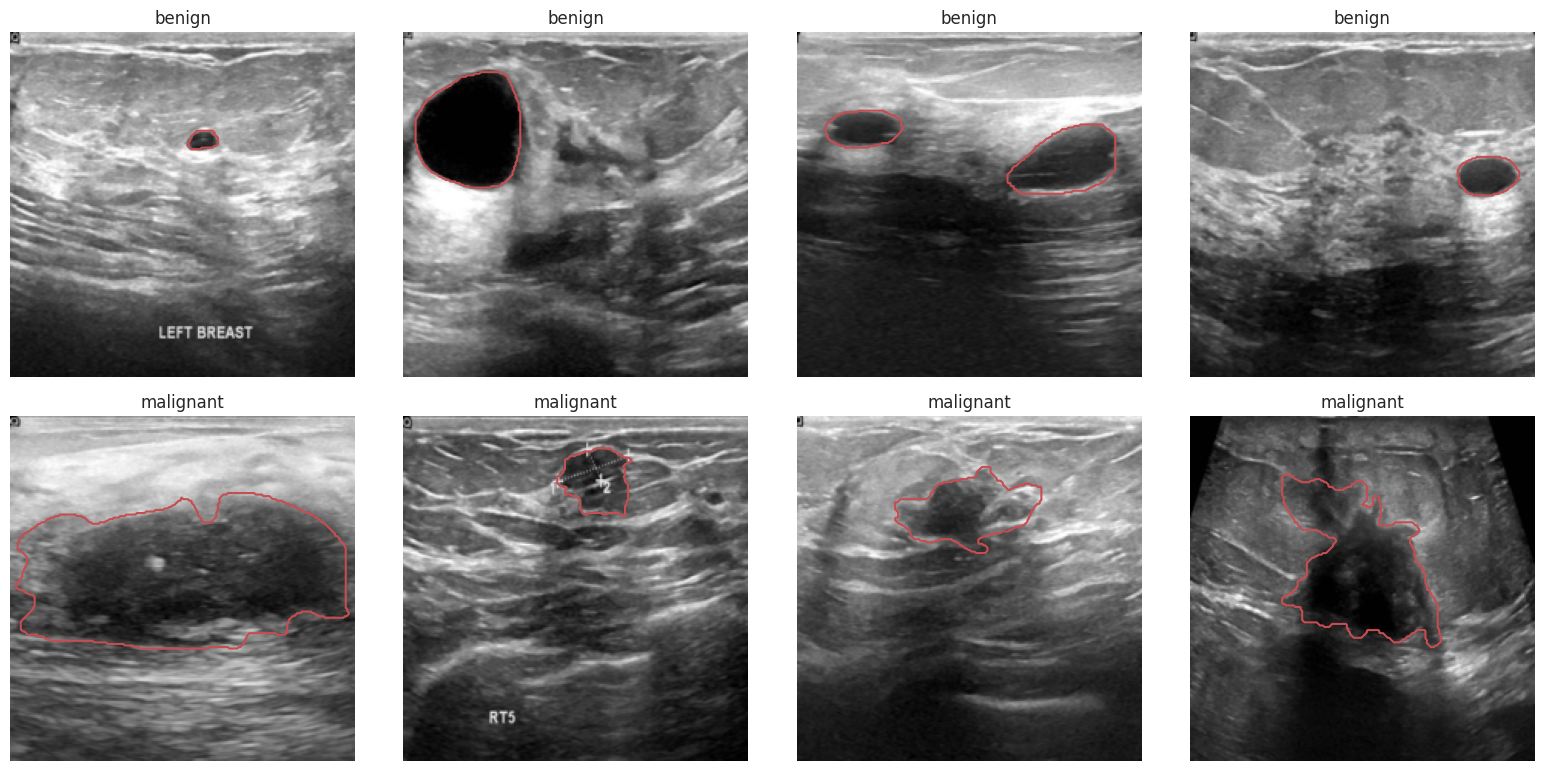

In [ ]:
# ---------- 3. Data (benign vs malignant, masks merged) + CV splits ----------
ROOT = None
for p in glob.glob('busi/**/benign', recursive=True):
    ROOT = os.path.dirname(p); break
assert ROOT is not None, 'BUSI folder not found'
rows = []
for cls in ['benign', 'malignant']:
    for f in sorted(glob.glob(f'{glob.escape(ROOT)}/{cls}/*.png')):
        if '_mask' in os.path.basename(f): continue
        masks = glob.glob(glob.escape(f[:-4]) + '_mask*.png')
        if len(masks): rows.append(dict(path=f, label=int(cls == 'malignant'), masks=masks))
df = pd.DataFrame(rows); print(df.label.value_counts().rename({0: 'benign', 1: 'malignant'}))

def load_item(path, mask_paths):
    img = np.array(Image.open(path).convert('L').resize((S, S), Image.BILINEAR))
    m = np.zeros((S, S), np.float32)
    for mp in mask_paths:
        m = np.maximum(m, (np.array(Image.open(mp).convert('L').resize((S, S), Image.NEAREST)) > 127).astype(np.float32))
    return img, m
items = [load_item(r.path, r.masks) for r in df.itertuples()]
X_all = torch.from_numpy(np.stack([i[0] for i in items]))[:, None]
M_all = torch.from_numpy(np.stack([i[1] for i in items]))[:, None]
y_all = torch.tensor(df.label.values)
keep = M_all.flatten(1).sum(1) > 0
X_all, M_all, y_all = X_all[keep], M_all[keep], y_all[keep]
N = len(y_all); y_np = y_all.numpy(); print('usable images:', N)

rskf = RepeatedStratifiedKFold(n_splits=CFG['N_SPLITS'], n_repeats=CFG['N_REPEATS'], random_state=42)
SPLITS = []
for k, (trv, te) in enumerate(rskf.split(np.zeros(N), y_np)):
    tr, va = train_test_split(trv, test_size=0.125, stratify=y_np[trv], random_state=k)
    SPLITS.append(dict(fold=k, tr=tr, va=va, te=te))
if CFG['MAX_FOLDS']: SPLITS = SPLITS[:CFG['MAX_FOLDS']]
print('folds:', len(SPLITS), '| sizes (tr/va/te):', len(SPLITS[0]['tr']), len(SPLITS[0]['va']), len(SPLITS[0]['te']))

def make_data(X, M, y, sp):
    d = {}
    for k, key in [('tr', 'tr'), ('va', 'va'), ('te', 'te')]:
        ii = sp[key]; d['X' + k], d['M' + k], d['y' + k] = X[ii].to(DEVICE), M[ii].to(DEVICE), y[ii].to(DEVICE)
    return d

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(2):
    sel = np.where(y_np == c)[0][:4]
    for j, s in enumerate(sel):
        ax[c, j].imshow(X_all[s, 0], cmap='gray'); ax[c, j].contour(M_all[s, 0], [0.5], colors='r', linewidths=1.5)
        ax[c, j].set_title(['benign', 'malignant'][c], fontsize=12); ax[c, j].axis('off')
plt.tight_layout(); plt.savefig(f'{FIG}/00_dataset_samples.png', dpi=200); plt.show()

In [ ]:
# ---------- 4. Backbones, preference-conditioned head, CAM, losses, augmentation ----------
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prep(x01): return (x01.repeat(1, 3, 1, 1) - MEAN) / STD
W_ = lambda m: m.DEFAULT if CFG['PRETRAINED'] else None

def build_backbone(arch, highres):
    tv = torchvision.models
    if arch == 'resnet18':
        r = tv.resnet18(weights=W_(tv.ResNet18_Weights)); C = 512
        if highres: r.layer4[0].conv1.stride = (1, 1); r.layer4[0].downsample[0].stride = (1, 1)
        return nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4), C, [r.layer4]
    if arch == 'resnet50':
        r = tv.resnet50(weights=W_(tv.ResNet50_Weights)); C = 2048
        if highres: r.layer4[0].conv2.stride = (1, 1); r.layer4[0].downsample[0].stride = (1, 1)
        return nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4), C, [r.layer4]
    if arch == 'densenet121':
        d = tv.densenet121(weights=W_(tv.DenseNet121_Weights))
        return nn.Sequential(d.features, nn.ReLU(inplace=False)), 1024, [d.features.denseblock4, d.features.norm5]
    if arch == 'efficientnet_b0':
        e = tv.efficientnet_b0(weights=W_(tv.EfficientNet_B0_Weights))
        return e.features, 1280, [e.features[-1], e.features[-2]]
    raise ValueError(arch)

class Net(nn.Module):
    """Backbone -> GAP -> linear. CAM = sum_k W[c,k] F_k (== Grad-CAM at last conv for GAP->linear heads).
    cond=True: FiLM on feature maps + preference-dependent classifier weights W(r)=W0 + r_exp*dW (tiny hypernetwork)."""
    def __init__(self, arch='resnet18', cond=False, highres=False):
        super().__init__()
        self.stem, C, last = build_backbone(arch, highres); self.last_mods = last
        self.fc = nn.Linear(C, 2); self.cond = cond
        if cond:
            self.film = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 2 * C))
            nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)
            self.dW = nn.Parameter(torch.zeros(2, C))
    def forward(self, x, pref=None):
        f = self.stem(x); B = x.size(0)
        if self.cond:
            g, b = self.film(pref).chunk(2, 1)
            f = f * (1 + g[:, :, None, None]) + b[:, :, None, None]
            W = self.fc.weight[None] + pref[:, 1, None, None] * self.dW[None]
        else:
            W = self.fc.weight[None].expand(B, -1, -1)
        logits = torch.einsum('bkc,bc->bk', W, f.mean((2, 3))) + self.fc.bias
        return logits, f, W

def cam_raw(f, W, cls):
    w = W[torch.arange(len(cls), device=f.device), cls]
    return (f * w[:, :, None, None]).sum(1, keepdim=True)
def up(c): return F.interpolate(c, size=(S, S), mode='bilinear', align_corners=False)
def norm_cam(c):
    c = F.relu(c); return c / (c.flatten(1).amax(1)[:, None, None, None] + 1e-6)
def exp_loss(cam, m, kind='dice'):
    inter = (cam * m).flatten(1).sum(1)
    if kind == 'dice': return (1 - (2 * inter + 1) / (cam.flatten(1).sum(1) + m.flatten(1).sum(1) + 1)).mean()
    return (1 - inter / (cam.flatten(1).sum(1) + 1e-6)).mean()
def dilate(m, px): return m if px <= 0 else F.max_pool2d(m, 2 * px + 1, 1, px)

def augment(x, m):
    B, dev = x.size(0), x.device
    r = lambda: torch.rand(B, device=dev) * 2 - 1
    ang, sc, tx, ty = r() * 10 * math.pi / 180, 1 + r() * 0.1, r() * 0.1, r() * 0.1
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    m = (F.grid_sample(m, grid, padding_mode='zeros', align_corners=False) > 0.5).float()
    x = (x * (1 + r().view(B, 1, 1, 1) * 0.2) + r().view(B, 1, 1, 1) * 0.1).clamp(0, 1)
    return x, m

def flat_grads(loss, params):
    gs = torch.autograd.grad(loss, params, retain_graph=True, allow_unused=True)
    return torch.cat([(g if g is not None else torch.zeros_like(p)).reshape(-1) for g, p in zip(gs, params)])
def set_grads(params, g):
    o = 0
    for p in params: n = p.numel(); p.grad = g[o:o + n].view_as(p).clone(); o += n
def mgda_alpha(gc, ge): return ((((ge - gc) @ ge) / (((gc - ge) ** 2).sum() + 1e-12))).clamp(0, 1)
def mgda_normalised(gc, ge):                      # normalise each gradient, min-norm, rescale by mean norm
    nc, ne = gc.norm() + 1e-12, ge.norm() + 1e-12
    gcn, gen = gc / nc, ge / ne; a = mgda_alpha(gcn, gen)
    return (a * gcn + (1 - a) * gen) * 0.5 * (nc + ne), a
def pcgrad(gc, ge):
    gs, orig = [gc.clone(), ge.clone()], [gc, ge]; order = [0, 1]; random.shuffle(order)
    for i in order:
        j = 1 - i; d = gs[i] @ orig[j]
        if d < 0: gs[i] -= d / (orig[j] @ orig[j] + 1e-12) * orig[j]
    return gs[0] + gs[1]

In [ ]:
# ---------- 5. Prediction, metrics (incl. threshold-free CAM AUC), faithfulness, mechanism tests ----------
def _pref(pref, B): return None if pref is None else torch.tensor(pref, device=DEVICE, dtype=torch.float32)[None].expand(B, 2)

@torch.no_grad()
def predict(model, X, pref=None, bs=64, is01=False):
    model.eval(); P, C = [], []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]; x = prep(xb if is01 else xb.float() / 255)
        logits, f, W = model(x, _pref(pref, len(x))); pr = F.softmax(logits, 1)
        C.append(norm_cam(up(cam_raw(f, W, pr.argmax(1))))); P.append(pr)
    return torch.cat(P), torch.cat(C)

def ece_bins(conf, correct, nb=10):
    edges = np.linspace(0.5, 1.0, nb + 1); b = np.clip(np.digitize(conf, edges[1:-1]), 0, nb - 1)
    acc = np.array([correct[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cf = np.array([conf[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cnt = np.array([(b == k).sum() for k in range(nb)])
    return np.nansum(np.abs(acc - cf) * cnt / len(conf)), cf, acc, cnt

def cam_pixel_auc(cams, M):                       # threshold-free localisation: AUROC of CAM vs. mask (56x56)
    c = F.avg_pool2d(cams, 4).flatten(1).cpu().numpy(); m = (F.avg_pool2d(M, 4) >= 0.5).flatten(1).cpu().numpy()
    return np.array([roc_auc_score(b, a) if 0 < b.sum() < len(b) else np.nan for a, b in zip(c, m)])

def compute_metrics(probs, y, cams, M):
    p1, yn = probs[:, 1].cpu().numpy(), y.cpu().numpy(); pred = (p1 >= 0.5).astype(int)
    tp, tn = ((pred == 1) & (yn == 1)).sum(), ((pred == 0) & (yn == 0)).sum()
    fp, fn = ((pred == 1) & (yn == 0)).sum(), ((pred == 0) & (yn == 1)).sum()
    conf = np.maximum(p1, 1 - p1); ece = ece_bins(conf, (pred == yn).astype(float))[0]
    cb = (cams >= 0.5).float(); inter = (cb * M).flatten(1).sum(1); union = ((cb + M) > 0).float().flatten(1).sum(1)
    iou = inter / union.clamp(min=1); dice = 2 * inter / (cb.flatten(1).sum(1) + M.flatten(1).sum(1)).clamp(min=1)
    energy = (cams * M).flatten(1).sum(1) / cams.flatten(1).sum(1).clamp(min=1e-6)
    am = cams.flatten(1).argmax(1); point = M.flatten(1).gather(1, am[:, None])[:, 0]
    cauc = cam_pixel_auc(cams, M)
    out = dict(auc=roc_auc_score(yn, p1), acc=(pred == yn).mean(), sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1),
               f1=2 * tp / max(2 * tp + fp + fn, 1), ece=ece, brier=float(((p1 - yn) ** 2).mean()),
               iou=iou.mean().item(), dice=dice.mean().item(), energy=energy.mean().item(), point=point.mean().item(),
               cam_auc=float(np.nanmean(cauc)))
    return out, iou.cpu().numpy(), cauc

def _trapz(y, x): return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))
@torch.no_grad()
def faithfulness(model, X, probs, cams, pref=None, n=None, patch=16):
    n = len(X) if n is None else min(n, len(X)); x = prep(X[:n].float() / 255); pc = probs[:n].argmax(1)
    g = F.avg_pool2d(cams[:n], patch).flatten(1); P = g.shape[1]
    rank = g.argsort(1, descending=True).argsort(1)
    blur = F.avg_pool2d(F.pad(x, (10, 10, 10, 10), mode='reflect'), 21, 1)
    fr = np.linspace(0, 1, 15); dl, ins = [], []; pr_ = _pref(pref, n)
    model.eval()
    for f in fr:
        k = int(round(f * P)); keepm = F.interpolate((rank < k).float().view(n, 1, S // patch, S // patch), scale_factor=patch, mode='nearest')
        dl.append(F.softmax(model(x * (1 - keepm), pr_)[0], 1)[torch.arange(n), pc].mean().item())
        ins.append(F.softmax(model(blur * (1 - keepm) + x * keepm, pr_)[0], 1)[torch.arange(n), pc].mean().item())
    return _trapz(np.array(dl), fr), _trapz(np.array(ins), fr)

def masked_inputs(X, M):                          # mechanism test: lesion-only vs. context-only inputs
    x = X.float() / 255; mu = x.mean((1, 2, 3), keepdim=True)
    return x * M + mu * (1 - M), x * (1 - M) + mu * M          # (lesion_only, context_only), both in [0,1]

def randomization_check(model, X, pref=None, n=50):
    m2 = copy.deepcopy(model)
    for mod in list(m2.last_mods) + [m2.fc]:
        for l in mod.modules():
            if hasattr(l, 'reset_parameters'): l.reset_parameters()
    _, c1 = predict(model, X[:n], pref); _, c2 = predict(m2, X[:n], pref)
    a, b = F.avg_pool2d(c1, 16).flatten(1).cpu().numpy(), F.avg_pool2d(c2, 16).flatten(1).cpu().numpy()
    rho = [abs(stats.spearmanr(a[i], b[i])[0]) for i in range(len(a)) if a[i].std() > 0 and b[i].std() > 0]
    return float(np.nanmean(rho))

def gradcam_equivalence(model, X, n=16):          # true Grad-CAM (autograd) vs. closed-form CAM
    model.eval(); x = prep(X[:n].float() / 255)
    with torch.enable_grad():
        logits, f, W = model(x); pc = logits.argmax(1)
        g = torch.autograd.grad(logits[torch.arange(len(x)), pc].sum(), f)[0]
        gc = F.relu((g.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True)).detach()
    cc = F.relu(cam_raw(f, W, pc)).detach()
    return F.cosine_similarity(gc.flatten(1), cc.flatten(1), dim=1).mean().item()

In [ ]:
# ---------- 6. Training (WS, MGDA raw, MGDA normalised, PCGrad, RRR, preference-conditioned) ----------
def train_run(method, lam, dil, kind, seed, data, arch='resnet18', highres=False, epochs=None, lr=None, verbose=False):
    """method: ws | mgda | mgda_n | pcgrad | rrr | pref."""
    epochs = epochs or CFG['EPOCHS']; lr = lr or CFG['LR']; set_seed(seed)
    model = Net(arch, cond=(method == 'pref'), highres=highres).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG['WD']); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ntr = len(data['ytr']); cnt = torch.bincount(data['ytr'], minlength=2).float(); cw = (ntr / (2 * cnt)).to(DEVICE); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(ntr, device=DEVICE); acc = dict(Lc=[], Le=[], cos=[], alpha=[])
        for i in range(0, ntr, CFG['BS']):
            idx = perm[i:i + CFG['BS']]
            if len(idx) < 4: continue
            x, m = augment(data['Xtr'][idx].float() / 255, data['Mtr'][idx]); y = data['ytr'][idx]
            xin = prep(x); r = None
            if method == 'pref': r = torch.distributions.Dirichlet(torch.full((2,), CFG['PREF_ALPHA'])).sample().to(DEVICE)
            if method == 'rrr': xin = xin.detach().requires_grad_(True)
            logits, f, W = model(xin, None if r is None else r[None].expand(len(idx), 2))
            Lc = F.cross_entropy(logits, y, weight=cw)
            cam = norm_cam(up(cam_raw(f, W, y))); Le = exp_loss(cam, dilate(m, dil), kind)
            if method == 'ws':
                loss = Lc + lam * Le; opt.zero_grad(); loss.backward()
            elif method == 'pref':
                loss = r[0] * Lc + r[1] * CFG['PREF_SCALE'] * Le; opt.zero_grad(); loss.backward()
            elif method == 'rrr':      # penalise input-gradient energy outside the (dilated) lesion
                g_in = torch.autograd.grad(F.log_softmax(logits, 1)[torch.arange(len(y)), y].sum(), xin, create_graph=True)[0]
                e = g_in.pow(2).sum(1, keepdim=True)
                Lr = ((e * (1 - dilate(m, dil))).flatten(1).sum(1) / (e.flatten(1).sum(1) + 1e-12)).mean()
                loss = Lc + lam * Lr; opt.zero_grad(); loss.backward()
            else:
                gc, ge = flat_grads(Lc, params), flat_grads(Le, params); acc['cos'].append(F.cosine_similarity(gc, ge, dim=0).item())
                if method == 'mgda':
                    a = mgda_alpha(gc, ge); g = a * gc + (1 - a) * ge
                elif method == 'mgda_n':
                    g, a = mgda_normalised(gc, ge)
                else:
                    g, a = pcgrad(gc, ge), torch.tensor(float('nan'))
                acc['alpha'].append(float(a)); opt.zero_grad(); set_grads(params, g)
            torch.nn.utils.clip_grad_norm_(params, 5.0); opt.step()
            acc['Lc'].append(Lc.item()); acc['Le'].append(Le.item())
        sched.step()
        pv, cv = predict(model, data['Xva'], [0.5, 0.5] if method == 'pref' else None); mv, _, _ = compute_metrics(pv, data['yva'], cv, data['Mva'])
        hist.append(dict(ep=ep + 1, Lc=np.mean(acc['Lc']), Le=np.mean(acc['Le']), val_auc=mv['auc'], val_iou=mv['iou'],
                         cos=np.mean(acc['cos']) if acc['cos'] else np.nan, alpha=np.nanmean(acc['alpha']) if acc['alpha'] else np.nan))
        if verbose: print({k: round(v, 4) for k, v in hist[-1].items()})
    return model, pd.DataFrame(hist)

t0 = time.time(); _d = make_data(X_all, M_all, y_all, SPLITS[0])
_m, _ = train_run('ws', 1.0, 0, 'dice', 0, _d, epochs=1, verbose=True)
print('Grad-CAM vs closed-form CAM cosine:', round(gradcam_equivalence(_m, _d['Xte']), 4), f'| {time.time() - t0:.0f}s'); del _m, _d

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 110MB/s]


{'ep': 1, 'Lc': np.float64(0.5038), 'Le': np.float64(0.6713), 'val_auc': np.float64(0.8636), 'val_iou': 0.3498, 'cos': nan, 'alpha': nan}
Grad-CAM vs closed-form CAM cosine: 1.0 | 7s


In [ ]:
# ---------- 7. Result logging, experiment grid, CV loop ----------
ROWS, HIST, POOL, MODELS = [], {}, {}, {}
def pool_add(name, te, probs, iou_i, cauc_i):
    d = POOL.setdefault(name, dict(p=np.zeros((N, 2)), iou=np.zeros(N), cauc=np.zeros(N), cnt=np.zeros(N)))
    d['p'][te] += probs.cpu().numpy(); d['iou'][te] += iou_i; d['cauc'][te] += np.nan_to_num(cauc_i); d['cnt'][te] += 1

def add_row(name, fam, fold, model, data, te, pref=None, extra=None):
    probs, cams = predict(model, data['Xte'], pref)
    m, iou_i, cauc_i = compute_metrics(probs, data['yte'], cams, data['Mte'])
    m['del_auc'], m['ins_auc'] = faithfulness(model, data['Xte'], probs, cams, pref, CFG['FAITH_N'])
    les, ctx = masked_inputs(data['Xte'], data['Mte']); yt = data['yte'].cpu().numpy()
    m['les_auc'] = roc_auc_score(yt, predict(model, les, pref, is01=True)[0][:, 1].cpu().numpy())
    m['ctx_auc'] = roc_auc_score(yt, predict(model, ctx, pref, is01=True)[0][:, 1].cpu().numpy())
    m.update(name=name, family=fam, fold=fold, **(extra or {})); ROWS.append(m); pool_add(name, te, probs, iou_i, cauc_i)

# (name, method, lambda, dilation, loss kind, family)
EXPS = [('baseline', 'ws', 0.0, 0, 'dice', 'WS')]
EXPS += [(f'ws_l{l:g}', 'ws', l, 0, 'dice', 'WS') for l in CFG['LAMBDAS']]
EXPS += [('mgda', 'mgda', 1, 0, 'dice', 'MGDA'), ('mgda_n', 'mgda_n', 1, 0, 'dice', 'MGDA-N'), ('pcgrad', 'pcgrad', 1, 0, 'dice', 'PCGrad'),
         ('rrr', 'rrr', CFG['RRR_LAMBDA'], 0, 'dice', 'RRR'), ('pref', 'pref', 1, 0, 'dice', 'PrefCond'),
         ('ws_l1_dil8', 'ws', 1.0, 8, 'dice', 'Ablation'), ('ws_l1_dil16', 'ws', 1.0, 16, 'dice', 'Ablation'), ('ws_l1_energy', 'ws', 1.0, 0, 'energy', 'Ablation')]
EXP = {e[0]: e for e in EXPS}

def run_exp(name, sp, data, arch='resnet18', highres=False, prefix='', fam=None, keep=False, lr=None):
    _, method, lam, dil, kind, family = EXP[name]; k = sp['fold']
    model, hist = train_run(method, lam, dil, kind, 100 + k, data, arch, highres, lr=lr)
    nm = prefix + name; HIST[(nm, k)] = hist
    if method == 'pref':
        for rr in CFG['PREF_GRID']: add_row(f'{prefix}pref_r{rr:.2f}', fam or family, k, model, data, sp['te'], pref=[1 - rr, rr])
    else:
        add_row(nm, fam or family, k, model, data, sp['te'])
    if keep and k == SPLITS[0]['fold']: MODELS[nm] = model
    return model

T0 = time.time()
if RUN['main']:
    for sp in SPLITS:
        data = make_data(X_all, M_all, y_all, sp)
        for name in EXP:
            m = run_exp(name, sp, data, keep=True);
            if sp['fold'] != SPLITS[0]['fold']: del m
            h = HIST[(name, sp['fold'])]
            print(f"[fold {sp['fold']}] {name:13s} | {time.time() - T0:5.0f}s | val AUC={h.val_auc.iloc[-1]:.3f} val IoU={h.val_iou.iloc[-1]:.3f}")
            torch.cuda.empty_cache()
        del data
pd.DataFrame(ROWS).to_csv(f'{OUT}/runs_main.csv', index=False)

[fold 0] baseline      |    32s | val AUC=0.979 val IoU=0.192
[fold 0] ws_l0.1       |    65s | val AUC=0.962 val IoU=0.365
[fold 0] ws_l0.5       |    99s | val AUC=0.986 val IoU=0.487
[fold 0] ws_l1         |   132s | val AUC=0.973 val IoU=0.520
[fold 0] ws_l2         |   165s | val AUC=0.960 val IoU=0.539
[fold 0] ws_l5         |   199s | val AUC=0.986 val IoU=0.564
[fold 0] ws_l10        |   232s | val AUC=0.991 val IoU=0.565
[fold 0] ws_l20        |   266s | val AUC=0.981 val IoU=0.568
[fold 0] ws_l50        |   299s | val AUC=0.938 val IoU=0.560
[fold 0] mgda          |   350s | val AUC=0.957 val IoU=0.557
[fold 0] mgda_n        |   402s | val AUC=0.960 val IoU=0.537
[fold 0] pcgrad        |   452s | val AUC=0.981 val IoU=0.516
[fold 0] rrr           |   548s | val AUC=0.915 val IoU=0.062
[fold 0] pref          |   609s | val AUC=0.953 val IoU=0.554
[fold 0] ws_l1_dil8    |   643s | val AUC=0.953 val IoU=0.439
[fold 0] ws_l1_dil16   |   678s | val AUC=0.972 val IoU=0.341
[fold 0]

In [ ]:
# ---------- 7b. Baseline with tuned learning rate (equal footing) ----------
if RUN['lr_tuned']:
    for sp in SPLITS:
        data = make_data(X_all, M_all, y_all, sp); best = None
        for lr in CFG['LR_GRID']:
            m, h = train_run('ws', 0.0, 0, 'dice', 100 + sp['fold'], data, lr=lr)
            if best is None or h.val_auc.iloc[-1] > best[0]: best = (h.val_auc.iloc[-1], lr, m)
        add_row('baseline_lrtuned', 'Baseline-tuned', sp['fold'], best[2], data, sp['te'], extra=dict(lr=best[1]))
        print(f"[fold {sp['fold']}] tuned baseline lr={best[1]} val AUC={best[0]:.3f}"); del best, data; torch.cuda.empty_cache()

RES = pd.DataFrame(ROWS); RES.to_csv(f'{OUT}/runs_all_test_metrics.csv', index=False)

[fold 0] tuned baseline lr=0.0001 val AUC=0.975
[fold 1] tuned baseline lr=0.0003 val AUC=0.971
[fold 2] tuned baseline lr=0.0003 val AUC=0.974
[fold 3] tuned baseline lr=0.0003 val AUC=0.985
[fold 4] tuned baseline lr=0.0003 val AUC=0.999


auc            acc           sens  \
family         name                                                            
Ablation       ws_l1_dil16       0.967 ± 0.021  0.915 ± 0.023  0.919 ± 0.049   
               ws_l1_dil8        0.969 ± 0.024   0.91 ± 0.028   0.89 ± 0.069   
               ws_l1_energy      0.964 ± 0.025  0.901 ± 0.024  0.914 ± 0.036   
Baseline-tuned baseline_lrtuned  0.957 ± 0.018   0.89 ± 0.031  0.881 ± 0.041   
MGDA           mgda              0.958 ± 0.021  0.892 ± 0.023  0.857 ± 0.091   
MGDA-N         mgda_n            0.958 ± 0.028  0.904 ± 0.015   0.91 ± 0.052   
PCGrad         pcgrad            0.961 ± 0.024  0.918 ± 0.015   0.91 ± 0.031   
PrefCond       pref_r0.00        0.964 ± 0.024  0.904 ± 0.018  0.905 ± 0.045   
               pref_r0.17        0.965 ± 0.024  0.904 ± 0.018  0.905 ± 0.045   
               pref_r0.33        0.965 ± 0.024  0.907 ± 0.017  0.905 ± 0.045   
               pref_r0.50        0.965 ± 0.024  0.904 ± 0.016   0.89 ± 0.055   
               pref_r0.67        0.964 ± 0.024  0.904 ± 0.016   0.89 ± 0.055   
               pref_r0.83        0.964 ± 0.025  0.903 ± 0.019  0.881 ± 0.058   
               pref_r1.00        0.964 ± 0.025  0.903 ± 0.016  0.862 ± 0.072   
RRR            rrr               0.903 ± 0.038  0.768 ± 0.067   0.89 ± 0.071   
WS             baseline          0.962 ± 0.025   0.909 ± 0.03   0.91 ± 0.052   
               ws_l0.1           0.967 ± 0.019  0.921 ± 0.021  0.938 ± 0.043   
               ws_l0.5           0.968 ± 0.014  0.924 ± 0.024  0.924 ± 0.052   
               ws_l1              0.966 ± 0.02  0.913 ± 0.009  0.895 ± 0.027   
               ws_l10             0.973 ± 0.02  0.921 ± 0.027  0.919 ± 0.043   
               ws_l2              0.969 ± 0.02  0.921 ± 0.014    0.9 ± 0.046   
               ws_l20            0.969 ± 0.016  0.887 ± 0.031   0.914 ± 0.06   
               ws_l5             0.961 ± 0.029  0.907 ± 0.035   0.89 ± 0.073   
               ws_l50            0.946 ± 0.018  0.887 ± 0.023  0.852 ± 0.062   

                                          spec             f1            ece  \
family         name                                                            
Ablation       ws_l1_dil16       0.913 ± 0.036  0.876 ± 0.031  0.065 ± 0.015   
               ws_l1_dil8         0.92 ± 0.032  0.865 ± 0.044   0.06 ± 0.021   
               ws_l1_energy      0.895 ± 0.021  0.857 ± 0.034  0.068 ± 0.024   
Baseline-tuned baseline_lrtuned  0.895 ± 0.032  0.839 ± 0.044  0.083 ± 0.024   
MGDA           mgda              0.908 ± 0.046  0.836 ± 0.037   0.066 ± 0.01   
MGDA-N         mgda_n            0.902 ± 0.015   0.86 ± 0.024   0.06 ± 0.015   
PCGrad         pcgrad             0.922 ± 0.01  0.878 ± 0.023  0.054 ± 0.015   
PrefCond       pref_r0.00        0.904 ± 0.034   0.86 ± 0.023  0.058 ± 0.015   
               pref_r0.17        0.904 ± 0.034   0.86 ± 0.023  0.057 ± 0.014   
               pref_r0.33        0.908 ± 0.034  0.864 ± 0.021  0.068 ± 0.017   
               pref_r0.50        0.911 ± 0.032  0.858 ± 0.023  0.061 ± 0.007   
               pref_r0.67        0.911 ± 0.025  0.858 ± 0.025   0.06 ± 0.008   
               pref_r0.83        0.913 ± 0.023  0.854 ± 0.029   0.07 ± 0.011   
               pref_r1.00        0.922 ± 0.025  0.851 ± 0.029  0.073 ± 0.003   
RRR            rrr               0.709 ± 0.117  0.717 ± 0.048  0.086 ± 0.013   
WS             baseline          0.908 ± 0.027  0.866 ± 0.043  0.071 ± 0.015   
               ws_l0.1           0.913 ± 0.023   0.885 ± 0.03  0.063 ± 0.019   
               ws_l0.5           0.924 ± 0.026  0.888 ± 0.035  0.058 ± 0.009   
               ws_l1             0.922 ± 0.015   0.87 ± 0.013  0.062 ± 0.018   
               ws_l10            0.922 ± 0.032  0.884 ± 0.037  0.061 ± 0.008   
               ws_l2             0.931 ± 0.012  0.881 ± 0.023  0.061 ± 0.012   
               ws_l20            0.874 ± 0.033   0.84 ± 0.044  0.068 ± 0.011   
               ws_l5             0.915 ± 0

,method,metric,mean_diff,ci_lo,ci_hi,p_t,dz,p_holm
0,ws_l0.1,auc,0.0042,-0.0071,0.0155,0.3593,0.4627,1.0000
1,ws_l0.5,auc,0.0058,-0.0149,0.0266,0.4784,0.3493,1.0000
2,ws_l1,auc,0.0035,-0.0079,0.0148,0.4474,0.3764,1.0000
3,ws_l2,auc,0.0070,-0.0085,0.0224,0.2777,0.5614,1.0000
4,ws_l5,auc,-0.0010,-0.0185,0.0165,0.8786,-0.0728,1.0000
5,ws_l10,auc,0.0101,-0.0077,0.0278,0.1901,0.7049,1.0000
6,ws_l20,auc,0.0065,-0.0087,0.0218,0.3009,0.5309,1.0000
7,ws_l50,auc,-0.0162,-0.0488,0.0164,0.2396,-0.6172,1.0000
8,mgda,auc,-0.0041,-0.0287,0.0205,0.6706,-0.2049,1.0000
9,mgda_n,auc,-0.0041,-0.0190,0.0107,0.4808,-0.3473,1.0000


,method,pooled_AUC,dAUC,dAUC_lo,dAUC_hi,IoU_gain,wilcoxon_p
0,ws_l0.1,0.9686,0.0063,-0.0012,0.0143,0.1644,0.0000
1,ws_l0.5,0.9706,0.0085,-0.0012,0.0196,0.2718,0.0000
2,ws_l1,0.9675,0.0054,-0.0063,0.0169,0.3025,0.0000
3,ws_l2,0.9697,0.0074,-0.0025,0.0179,0.3266,0.0000
4,ws_l5,0.9624,0.0002,-0.0096,0.0099,0.3422,0.0000
5,ws_l10,0.9730,0.0107,-0.0002,0.0216,0.3460,0.0000
6,ws_l20,0.9681,0.0057,-0.0051,0.0179,0.3472,0.0000
7,ws_l50,0.9457,-0.0162,-0.0326,0.0006,0.3518,0.0000
8,mgda,0.9534,-0.0088,-0.0238,0.0065,0.3425,0.0000
9,mgda_n,0.9586,-0.0037,-0.0160,0.0080,0.3262,0.0000


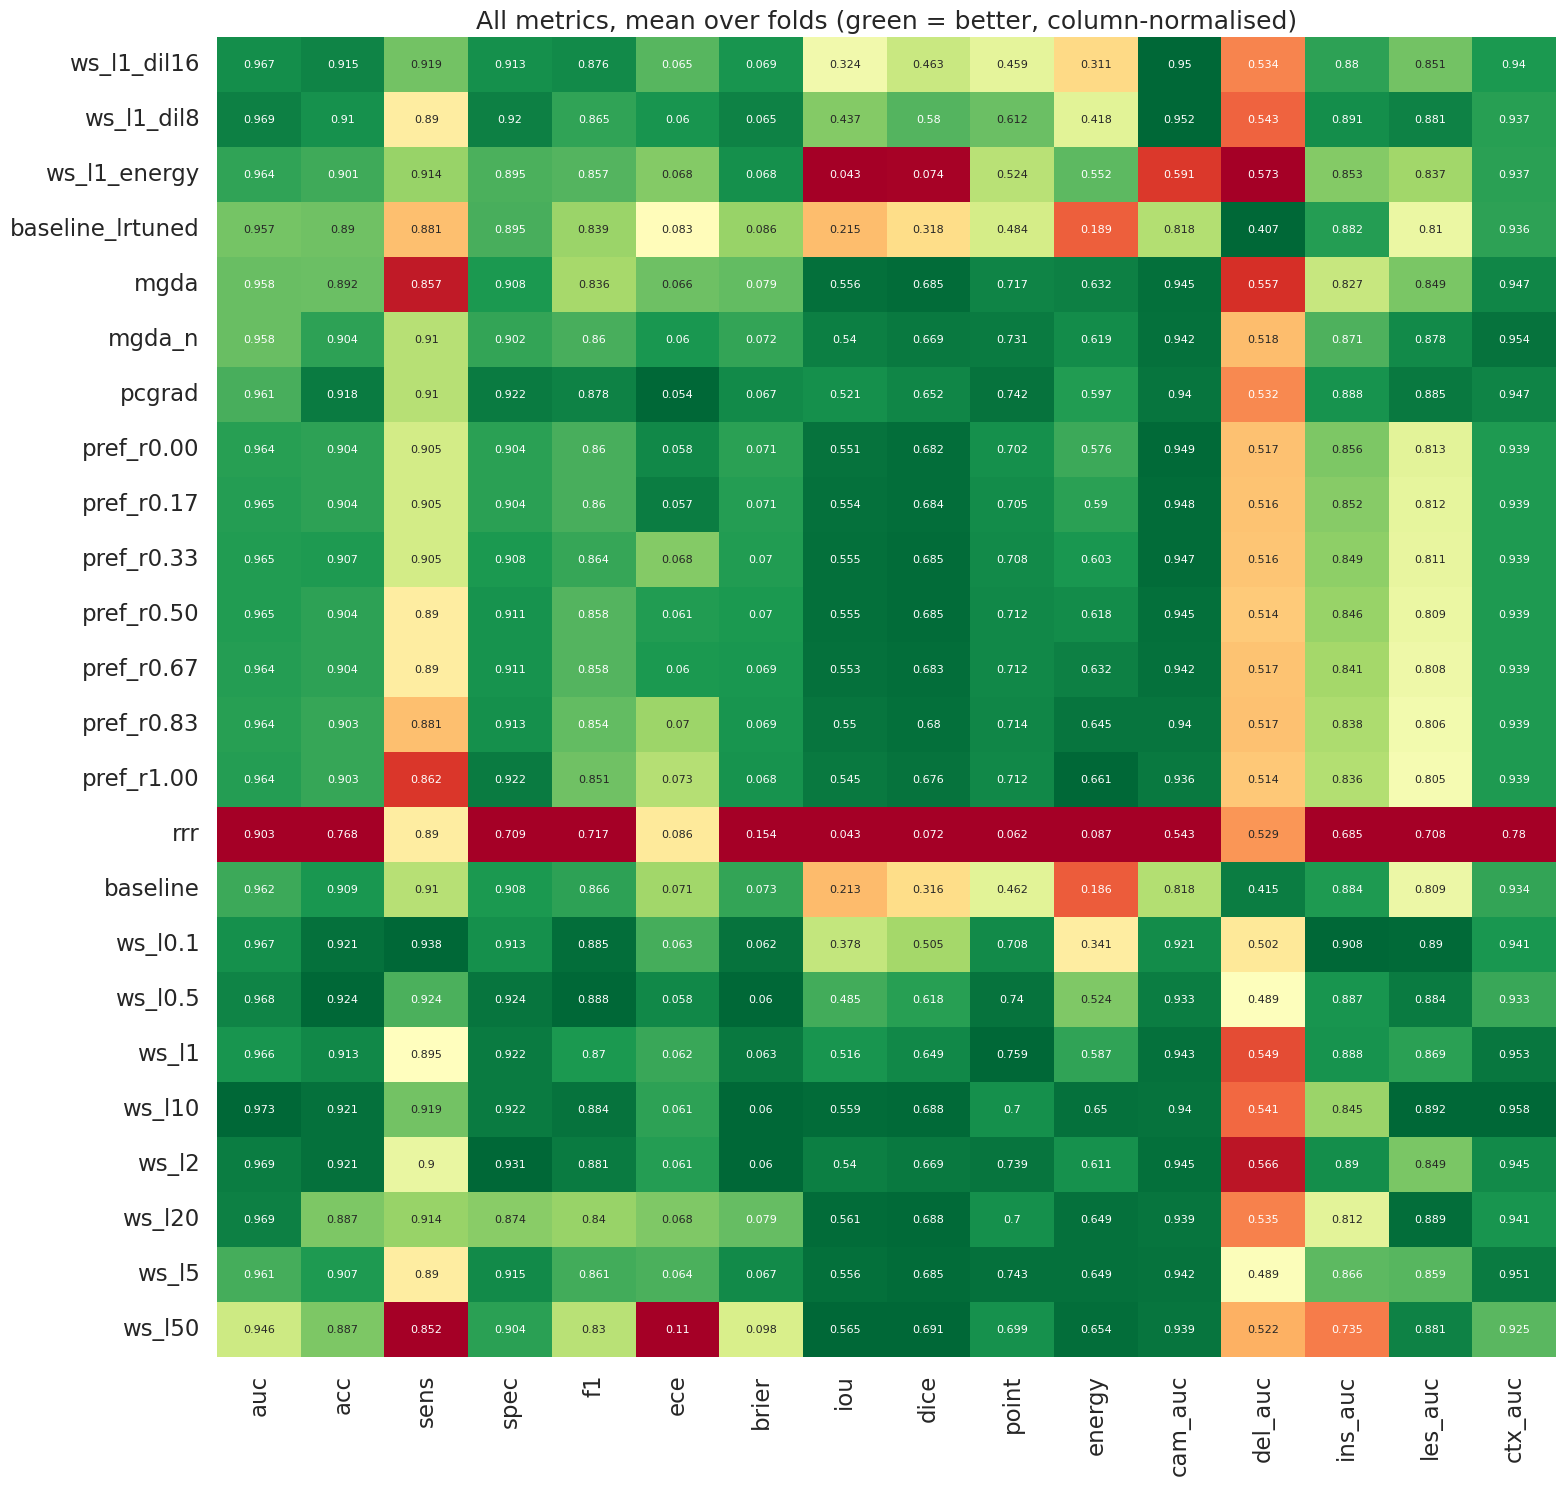

In [9]:
# ---------- 8. Summary table + paired statistics ----------
cols = ['auc', 'acc', 'sens', 'spec', 'f1', 'ece', 'brier', 'iou', 'dice', 'point', 'energy', 'cam_auc', 'del_auc', 'ins_auc', 'les_auc', 'ctx_auc']
core = RES[~RES.name.str.contains(r'\|')]
g = core.groupby(['family', 'name'])[cols]
SUM = g.mean().round(3).astype(str) + ' ± ' + g.std().fillna(0).round(3).astype(str)
SUM.to_csv(f'{OUT}/summary_mean_sd_over_folds.csv'); display(SUM)
MEANS = core.groupby(['family', 'name'])[cols].mean().reset_index()

def holm(p):
    p = np.asarray(p); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for r, i in enumerate(o): run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

def paired_vs_baseline(metric, names):
    b = core[core.name == 'baseline'].sort_values('fold')[metric].values; rows_ = []
    for n in names:
        v = core[core.name == n].sort_values('fold')[metric].values
        if len(v) != len(b) or len(b) < 2: continue
        d = v - b; t, p = stats.ttest_rel(v, b); ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d)) if d.std() > 0 else (d.mean(), d.mean())
        rows_.append(dict(method=n, metric=metric, mean_diff=d.mean(), ci_lo=ci[0], ci_hi=ci[1], p_t=p, dz=d.mean() / (d.std(ddof=1) + 1e-12)))
    out = pd.DataFrame(rows_); out['p_holm'] = holm(out.p_t.values) if len(out) else []; return out
cmp_names = [n for n in core.name.unique() if n != 'baseline' and not n.startswith('pref_r')] + ['pref_r0.50']
PAIRED = pd.concat([paired_vs_baseline(m, cmp_names) for m in ['auc', 'iou', 'cam_auc', 'del_auc', 'ins_auc', 'sens', 'spec', 'ece']])
PAIRED.to_csv(f'{OUT}/paired_vs_baseline_folds.csv', index=False); display(PAIRED[PAIRED.metric.isin(['auc', 'iou', 'ins_auc'])].round(4))

# pooled out-of-fold analysis (every image tested exactly once per repeat)
TESTED = POOL['baseline']['cnt'] > 0; y_T = y_np[TESTED]; N_T = int(TESTED.sum())
def pooled(name):
    d = POOL[name]; c = np.maximum(d['cnt'], 1); return (d['p'][:, 1] / c)[TESTED], (d['iou'] / c)[TESTED]
rng = np.random.default_rng(0); pooled_rows = []; pb, pi = pooled('baseline')
for n in [n for n in POOL if n != 'baseline' and '|' not in n and not n.startswith('pref_r') or n == 'pref_r0.50']:
    p1, iou_i = pooled(n); w = stats.wilcoxon(iou_i, pi).pvalue; diffs = []
    for _ in range(1000):
        bi = rng.integers(0, N_T, N_T)
        if len(np.unique(y_T[bi])) == 2: diffs.append(roc_auc_score(y_T[bi], p1[bi]) - roc_auc_score(y_T[bi], pb[bi]))
    pooled_rows.append(dict(method=n, pooled_AUC=roc_auc_score(y_T, p1), dAUC=np.mean(diffs), dAUC_lo=np.percentile(diffs, 2.5), dAUC_hi=np.percentile(diffs, 97.5),
                            IoU_gain=float((iou_i - pi).mean()), wilcoxon_p=w))
POOLED = pd.DataFrame(pooled_rows); POOLED.to_csv(f'{OUT}/pooled_oof_stats.csv', index=False); display(POOLED.round(4))

fig, ax = plt.subplots(figsize=(16, 0.55 * len(MEANS) + 2)); hm = MEANS.set_index('name')[cols]; hmn = (hm - hm.min()) / (hm.max() - hm.min() + 1e-9)
for c in ['ece', 'brier', 'del_auc', 'ctx_auc']: hmn[c] = 1 - hmn[c] if c != 'ctx_auc' else hmn[c]
sns.heatmap(hmn, annot=hm.round(3), fmt='', cmap='RdYlGn', cbar=False, ax=ax, annot_kws={'size': 8}); ax.set_ylabel('')
ax.set_title('All metrics, mean over folds (green = better, column-normalised)'); plt.tight_layout(); plt.savefig(f'{FIG}/01_metrics_heatmap.png', dpi=200); plt.show()

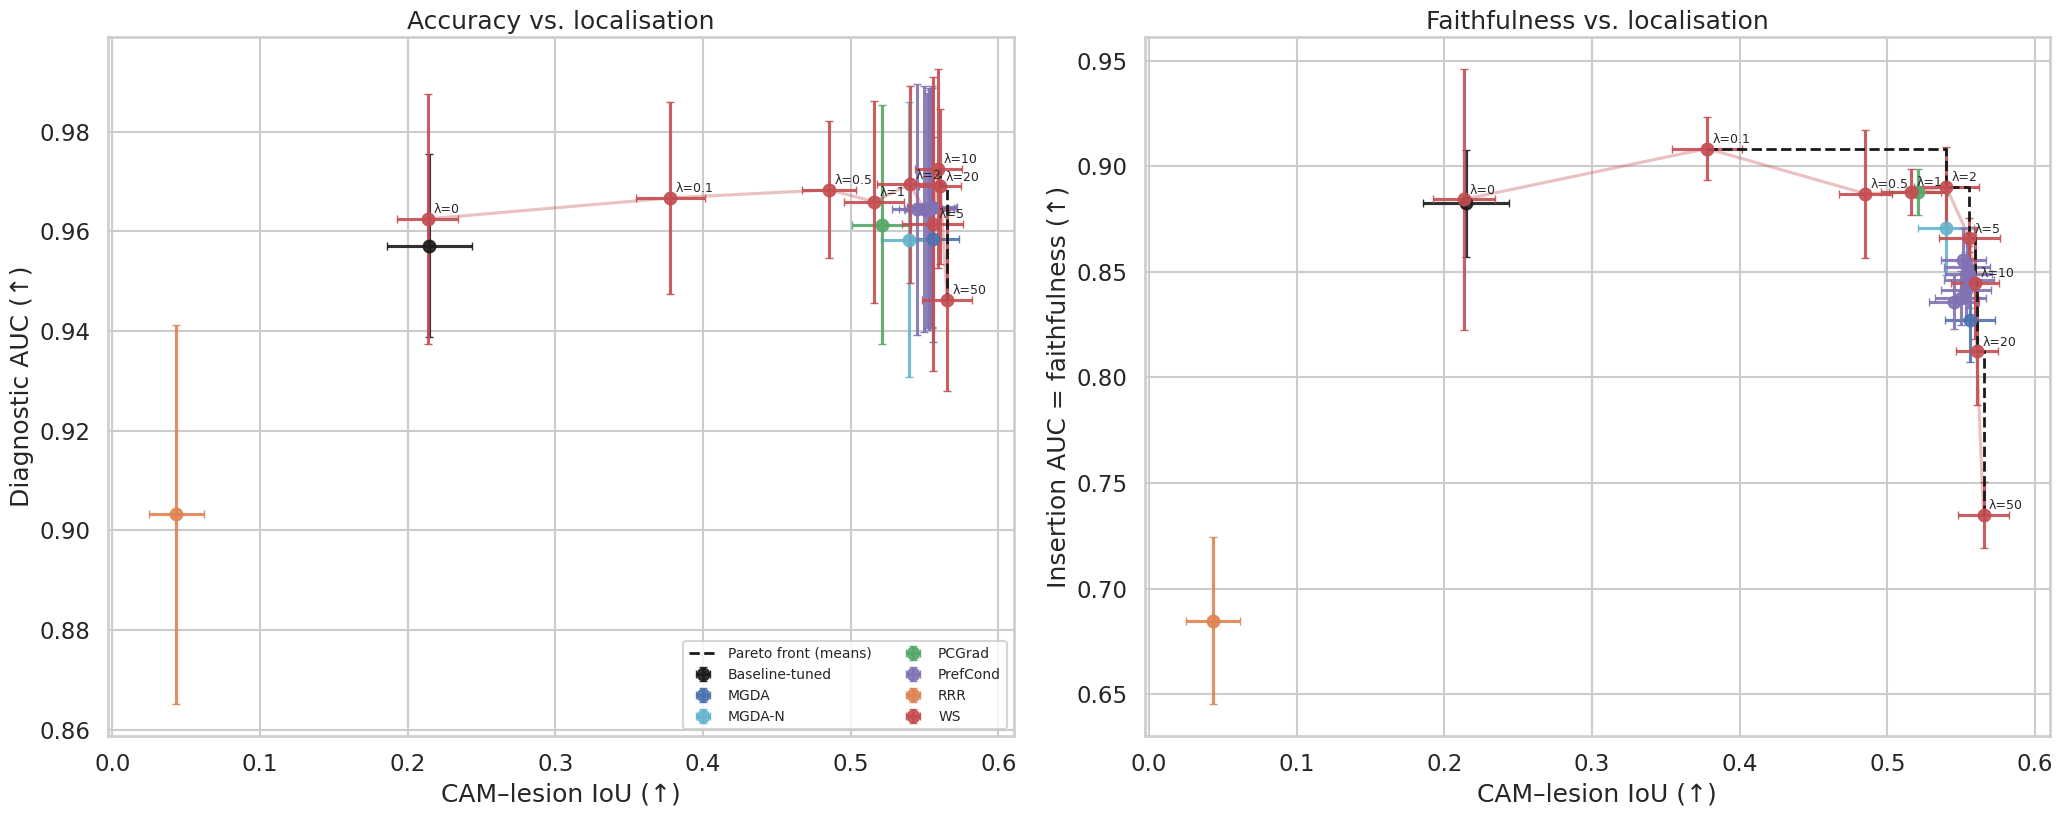

HV_auc_iou         HV_ins_iou        
                   mean     std       mean     std
method                                            
All              0.2717  0.0132     0.5158  0.0135
MGDA             0.2547  0.0101     0.4596  0.0148
MGDA-N           0.2473  0.0174     0.4698  0.0231
PCGrad           0.2404  0.0174     0.4624  0.0154
PrefCond         0.2588  0.0172     0.4757  0.0126
RRR              0.0173  0.0069     0.0302  0.0140
WS (λ sweep)     0.2709  0.0148     0.5137  0.0164

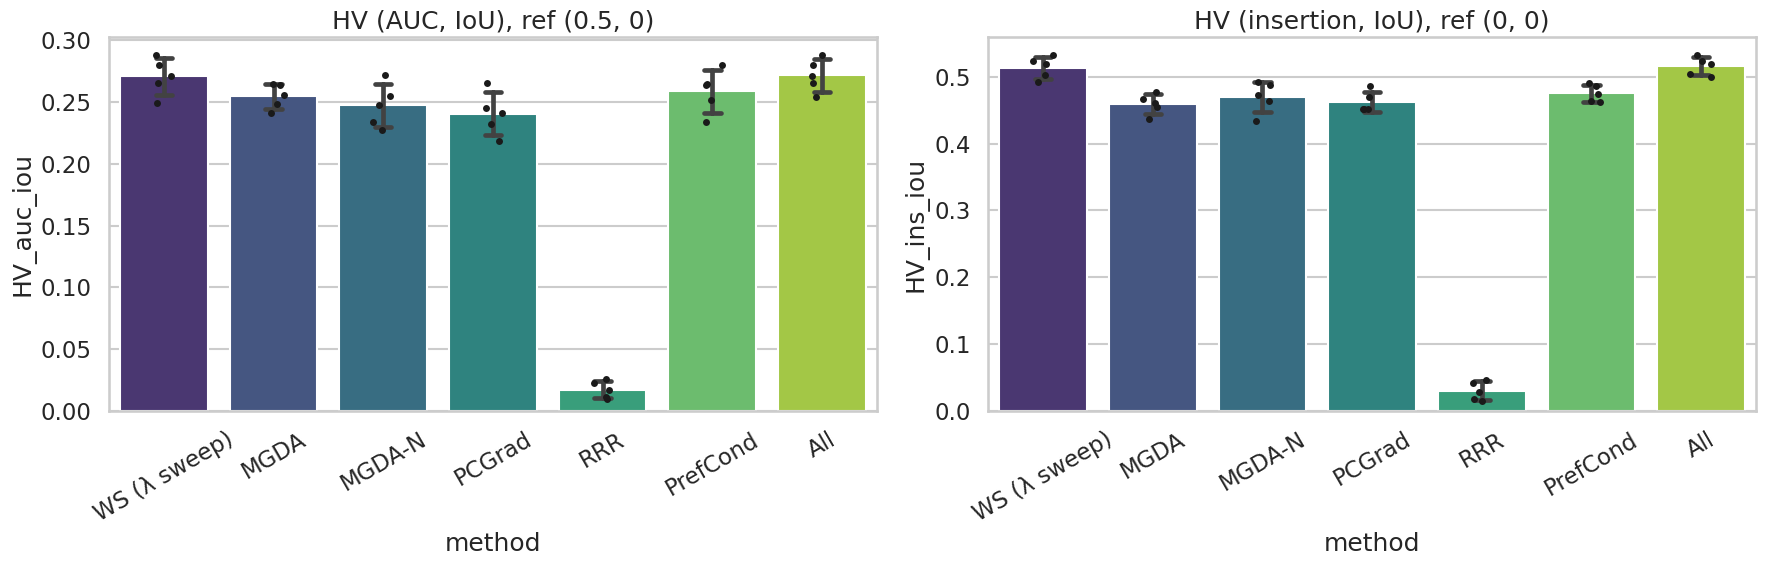

In [10]:
# ---------- 9. Pareto fronts + hypervolume (per fold) ----------
FAMCOL = {'WS': 'C3', 'MGDA': 'C0', 'MGDA-N': 'C9', 'PCGrad': 'C2', 'RRR': 'C1', 'PrefCond': 'C4', 'Baseline-tuned': 'k'}
def nondominated(P):
    P = np.asarray(P); return [i for i, p in enumerate(P) if not any((q >= p).all() and (q > p).any() for j, q in enumerate(P) if j != i)]
def hv2d(points, ref):
    pts = sorted([p for p in points if p[0] > ref[0] and p[1] > ref[1]], key=lambda p: -p[0]); hv, by = 0.0, ref[1]
    for x, y in pts:
        if y > by: hv += (x - ref[0]) * (y - by); by = y
    return hv

ST = core.groupby(['family', 'name'])[['auc', 'iou', 'ins_auc']].agg(['mean', 'std']).fillna(0).reset_index()
ST.columns = ['family', 'name', 'auc', 'auc_sd', 'iou', 'iou_sd', 'ins', 'ins_sd']; ST = ST[ST.family != 'Ablation'].reset_index(drop=True)
fig, axs = plt.subplots(1, 2, figsize=(21, 8.5))
for a, (yc, ysd, yl) in zip(axs, [('auc', 'auc_sd', 'Diagnostic AUC (↑)'), ('ins', 'ins_sd', 'Insertion AUC = faithfulness (↑)')]):
    for fam, d in ST.groupby('family'):
        a.errorbar(d.iou, d[yc], xerr=d.iou_sd, yerr=d[ysd], fmt='o', color=FAMCOL.get(fam, 'gray'), ms=9, capsize=3, alpha=.9, label=fam)
        if fam == 'WS':
            dd = d.sort_values('iou'); a.plot(dd.iou, dd[yc], '-', color=FAMCOL['WS'], alpha=.35)
            for _, r in dd.iterrows(): a.annotate(r['name'].replace('ws_l', 'λ=').replace('baseline', 'λ=0'), (r.iou, r[yc]), fontsize=9, xytext=(4, 4), textcoords='offset points')
    nd = nondominated(ST[['iou', yc]].values); f_ = ST.iloc[nd].sort_values('iou'); a.step(f_.iou, f_[yc], where='post', color='k', ls='--', lw=2, label='Pareto front (means)')
    a.set_xlabel('CAM–lesion IoU (↑)'); a.set_ylabel(yl)
axs[0].set_title('Accuracy vs. localisation'); axs[1].set_title('Faithfulness vs. localisation'); axs[0].legend(fontsize=10, ncol=2)
plt.tight_layout(); plt.savefig(f'{FIG}/02_pareto_fronts.png', dpi=200); plt.show()

fam_sets = {'WS (λ sweep)': lambda n, f: f == 'WS', 'MGDA': lambda n, f: f == 'MGDA', 'MGDA-N': lambda n, f: f == 'MGDA-N', 'PCGrad': lambda n, f: f == 'PCGrad',
            'RRR': lambda n, f: f == 'RRR', 'PrefCond': lambda n, f: f == 'PrefCond', 'All': lambda n, f: f not in ('Ablation', 'Baseline-tuned')}
hv_rows = []
for fold in sorted(core.fold.unique()):
    d = core[core.fold == fold]
    for k, fn in fam_sets.items():
        s = d[[fn(n, f) for n, f in zip(d.name, d.family)]]
        hv_rows.append(dict(method=k, fold=fold, HV_auc_iou=hv2d(list(zip(s.auc, s.iou)), (0.5, 0.0)), HV_ins_iou=hv2d(list(zip(s.ins_auc, s.iou)), (0.0, 0.0))))
HV = pd.DataFrame(hv_rows); HV.to_csv(f'{OUT}/hypervolume.csv', index=False); display(HV.groupby('method')[['HV_auc_iou', 'HV_ins_iou']].agg(['mean', 'std']).round(4))
fig, axs = plt.subplots(1, 2, figsize=(18, 6))
for a, c, t in zip(axs, ['HV_auc_iou', 'HV_ins_iou'], ['HV (AUC, IoU), ref (0.5, 0)', 'HV (insertion, IoU), ref (0, 0)']):
    sns.barplot(data=HV, x='method', y=c, errorbar='sd', capsize=.15, palette='viridis', ax=a); sns.stripplot(data=HV, x='method', y=c, color='k', size=5, ax=a); a.set_title(t); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{FIG}/03_hypervolume.png', dpi=200); plt.show()

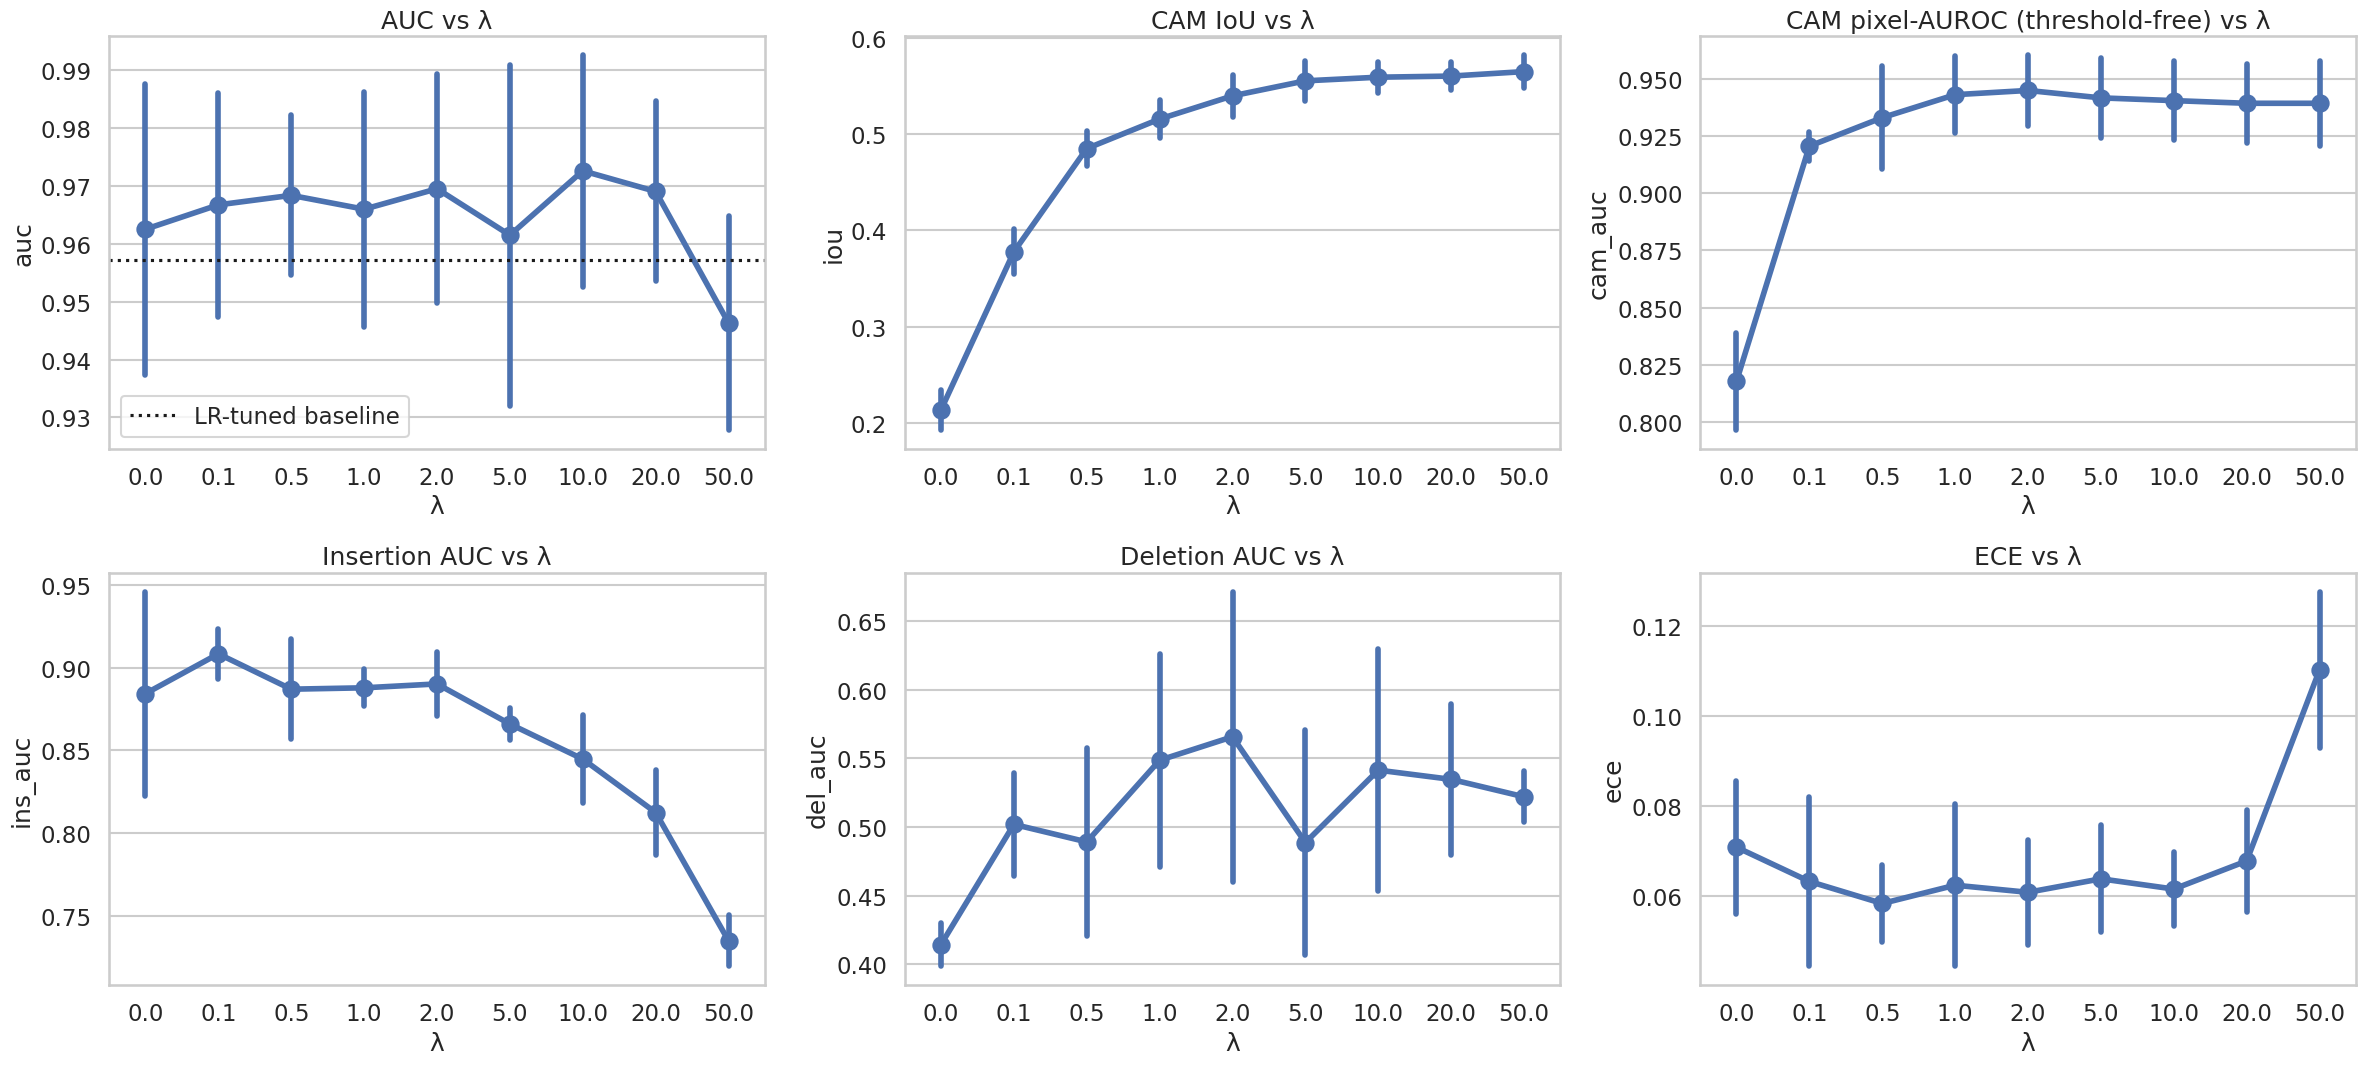

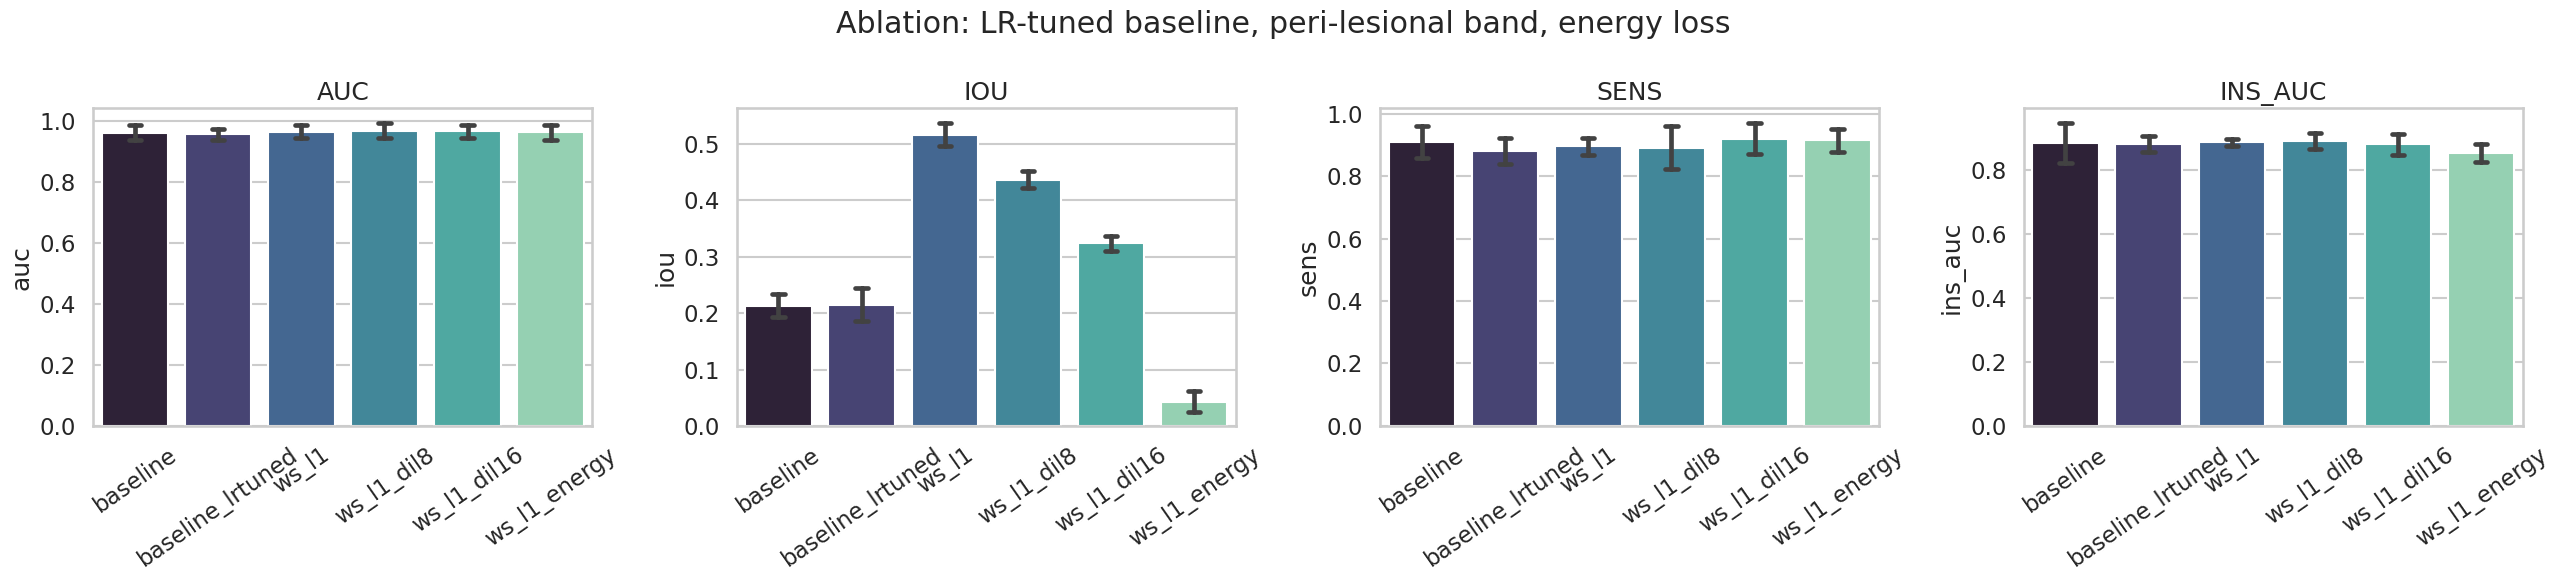

In [11]:
# ---------- 10. Extended λ sweep (look for the knee), tuned baseline, ablations ----------
ws = core[core.name.isin(['baseline'] + [f'ws_l{l:g}' for l in CFG['LAMBDAS']])].copy()
ws['lam'] = ws.name.map(lambda n: 0.0 if n == 'baseline' else float(n.replace('ws_l', '')))
fig, axs = plt.subplots(2, 3, figsize=(24, 11))
for a, (c, t) in zip(axs.ravel(), [('auc', 'AUC'), ('iou', 'CAM IoU'), ('cam_auc', 'CAM pixel-AUROC (threshold-free)'), ('ins_auc', 'Insertion AUC'), ('del_auc', 'Deletion AUC'), ('ece', 'ECE')]):
    sns.pointplot(data=ws, x='lam', y=c, errorbar='sd', ax=a, color='C0'); a.set_title(t + ' vs λ'); a.set_xlabel('λ')
    if c == 'auc':
        tb = core[core.name == 'baseline_lrtuned'].auc.mean() if (core.name == 'baseline_lrtuned').any() else None
        if tb: a.axhline(tb, color='k', ls=':', label='LR-tuned baseline'); a.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/04_lambda_sweep_extended.png', dpi=200); plt.show()
ab = core[core.name.isin(['baseline', 'baseline_lrtuned', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy'])]; order = [n for n in ['baseline', 'baseline_lrtuned', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy'] if n in ab.name.values]
fig, axs = plt.subplots(1, 4, figsize=(26, 6))
for a, c in zip(axs, ['auc', 'iou', 'sens', 'ins_auc']):
    sns.barplot(data=ab, x='name', y=c, order=order, errorbar='sd', capsize=.15, palette='mako', ax=a); a.tick_params(axis='x', rotation=35); a.set_title(c.upper()); a.set_xlabel('')
plt.suptitle('Ablation: LR-tuned baseline, peri-lesional band, energy loss'); plt.tight_layout(); plt.savefig(f'{FIG}/05_ablations.png', dpi=200); plt.show()

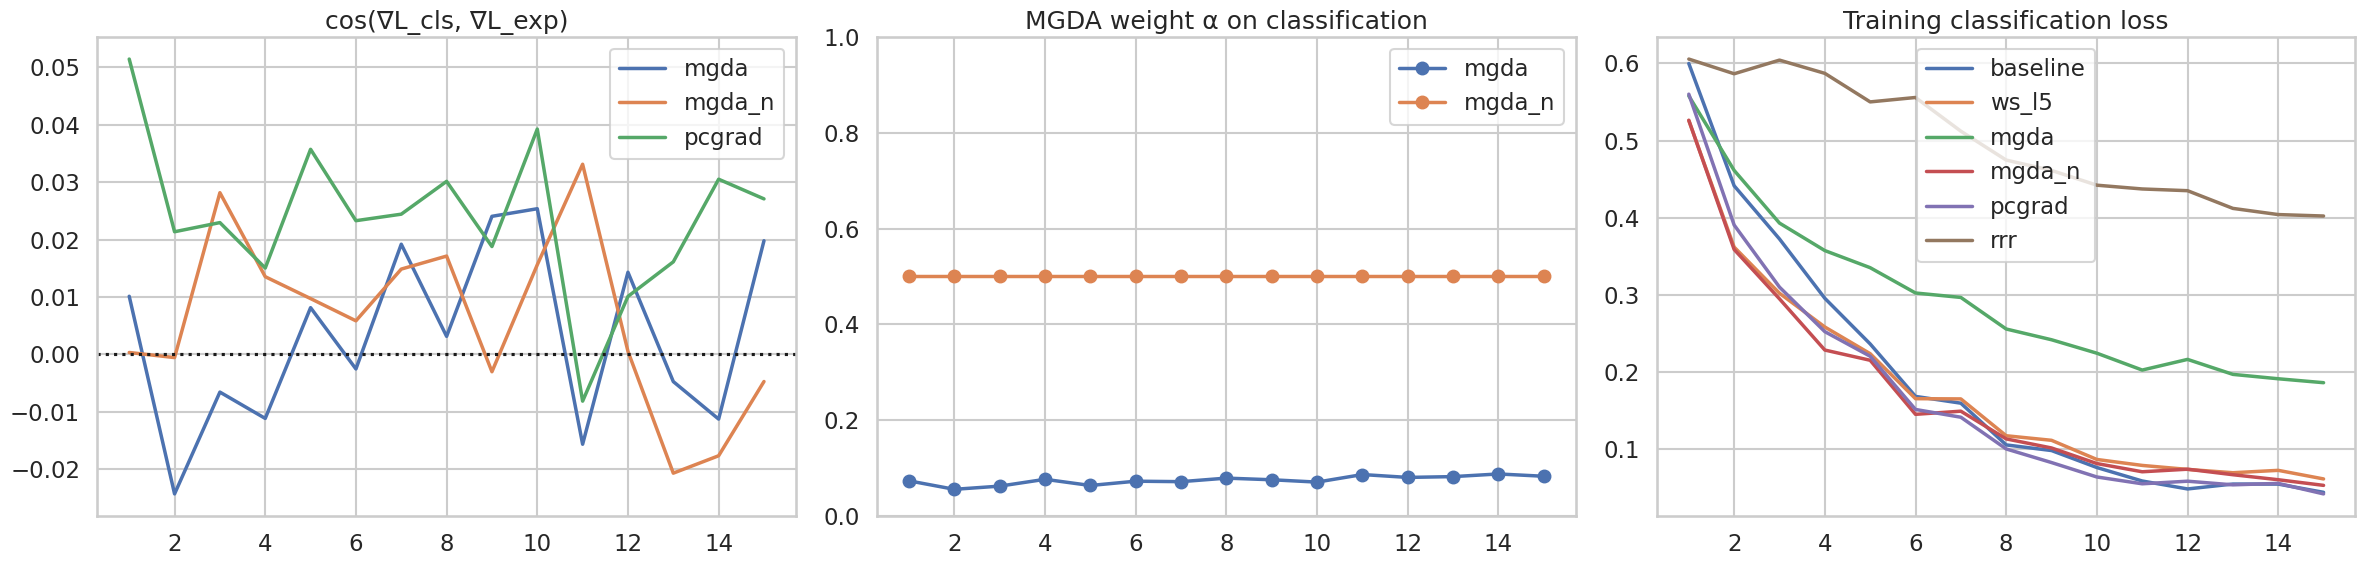

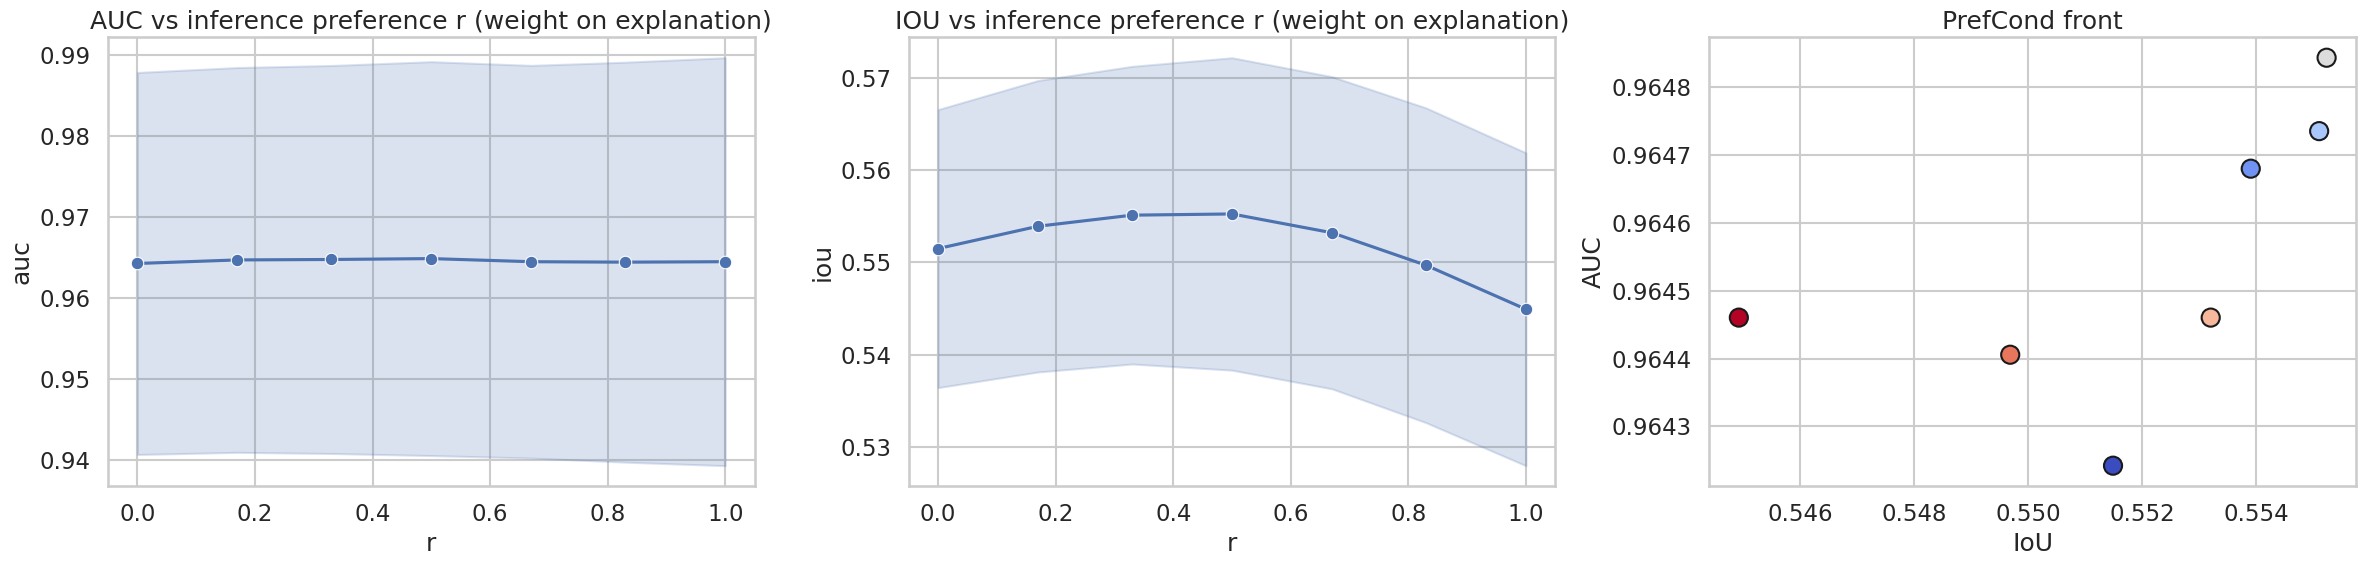

Preference-model diagnostics (fold 0): {'mean_abs_prob_change': 0.022677192464470863, 'cam_cosine_r0_vs_r1': 0.9564906358718872, 'dW_norm': 0.2685955762863159, 'film_last_weight_norm': 1.752679467201233}


In [12]:
# ---------- 11. Optimisers: gradient conflict, MGDA weights, preference-model diagnostics ----------
fig, axs = plt.subplots(1, 3, figsize=(24, 6))
for n in ['mgda', 'mgda_n', 'pcgrad']:
    hh = pd.concat([HIST[(n, k)] for k in sorted({k for (nn, k) in HIST if nn == n})]).groupby('ep').mean()
    axs[0].plot(hh.index, hh.cos, lw=2.5, label=n)
    if n != 'pcgrad': axs[1].plot(hh.index, hh.alpha, lw=2.5, marker='o', label=n)
axs[0].axhline(0, color='k', ls=':'); axs[0].set_title('cos(∇L_cls, ∇L_exp)'); axs[0].legend(); axs[1].set_title('MGDA weight α on classification'); axs[1].set_ylim(0, 1); axs[1].legend()
for n in ['baseline', 'ws_l5', 'mgda', 'mgda_n', 'pcgrad', 'rrr']:
    hh = pd.concat([HIST[(n, k)] for k in sorted({k for (nn, k) in HIST if nn == n})]).groupby('ep').mean(); axs[2].plot(hh.index, hh.Lc, lw=2.5, label=n)
axs[2].set_title('Training classification loss'); axs[2].legend(); plt.tight_layout(); plt.savefig(f'{FIG}/06_gradient_conflict_and_mgda.png', dpi=200); plt.show()

pf = core[core.family == 'PrefCond'].copy(); pf['r'] = pf.name.str.replace('pref_r', '').astype(float)
fig, axs = plt.subplots(1, 3, figsize=(24, 6))
for a, c in zip(axs[:2], ['auc', 'iou']): sns.lineplot(data=pf, x='r', y=c, marker='o', errorbar='sd', ax=a); a.set_title(f'{c.upper()} vs inference preference r (weight on explanation)')
axs[2].scatter(pf.groupby('r').iou.mean(), pf.groupby('r').auc.mean(), c=sorted(pf.r.unique()), cmap='coolwarm', s=170, edgecolor='k'); axs[2].set_xlabel('IoU'); axs[2].set_ylabel('AUC'); axs[2].set_title('PrefCond front')
plt.tight_layout(); plt.savefig(f'{FIG}/07_preference_conditioned.png', dpi=200); plt.show()
if 'pref' in MODELS:                              # diagnostic: does the model actually use the preference?
    d0 = make_data(X_all, M_all, y_all, SPLITS[0]); pa, ca = predict(MODELS['pref'], d0['Xte'], [1, 0]); pb_, cb_ = predict(MODELS['pref'], d0['Xte'], [0, 1])
    diag = dict(mean_abs_prob_change=float((pa - pb_).abs().mean()), cam_cosine_r0_vs_r1=float(F.cosine_similarity(ca.flatten(1), cb_.flatten(1)).mean()),
                dW_norm=float(MODELS['pref'].dW.norm()), film_last_weight_norm=float(MODELS['pref'].film[-1].weight.norm()))
    json.dump(diag, open(f'{OUT}/pref_model_diagnostics.json', 'w'), indent=1); print('Preference-model diagnostics (fold 0):', diag); del d0

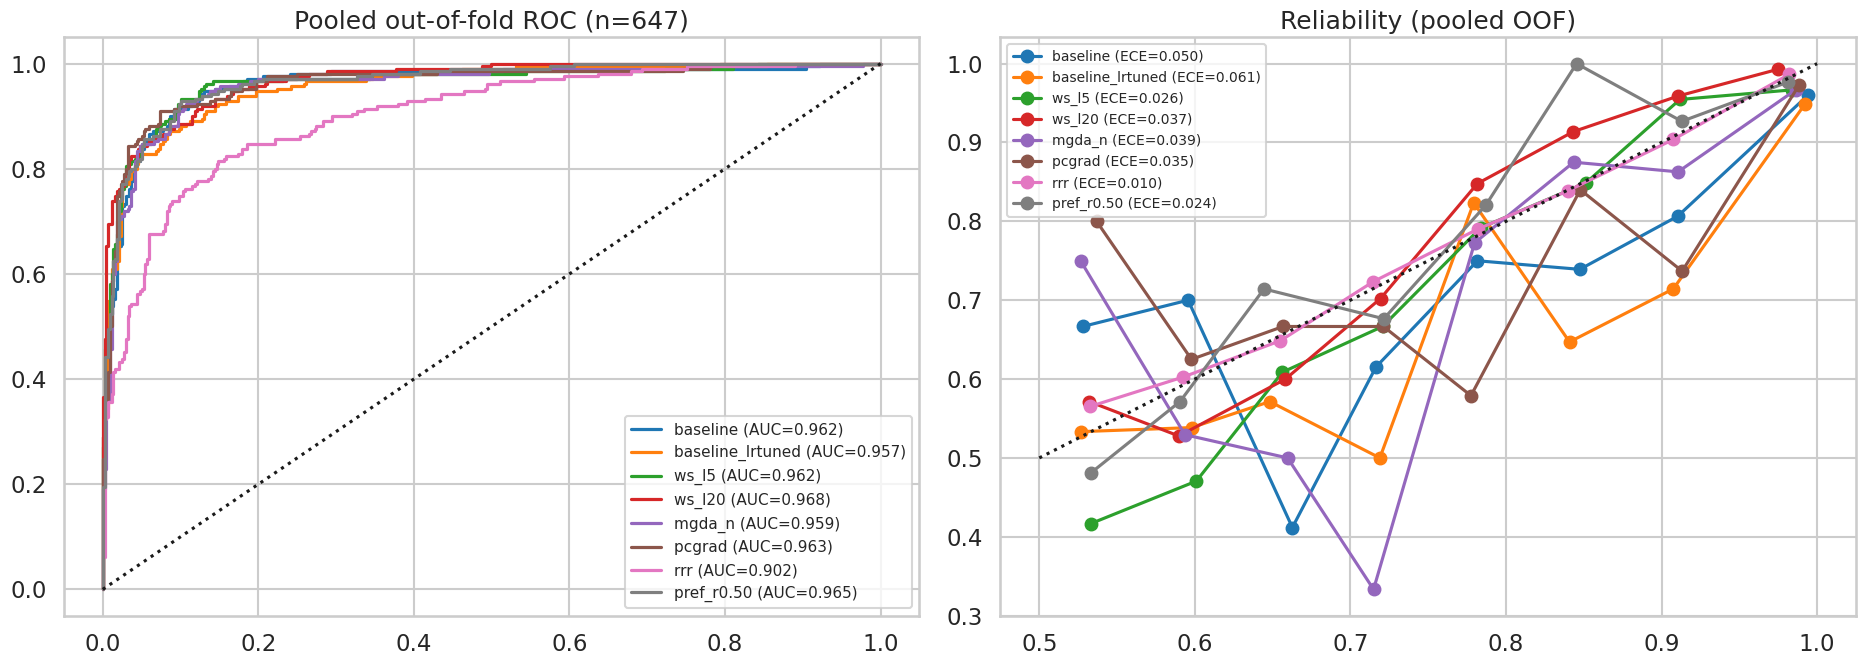

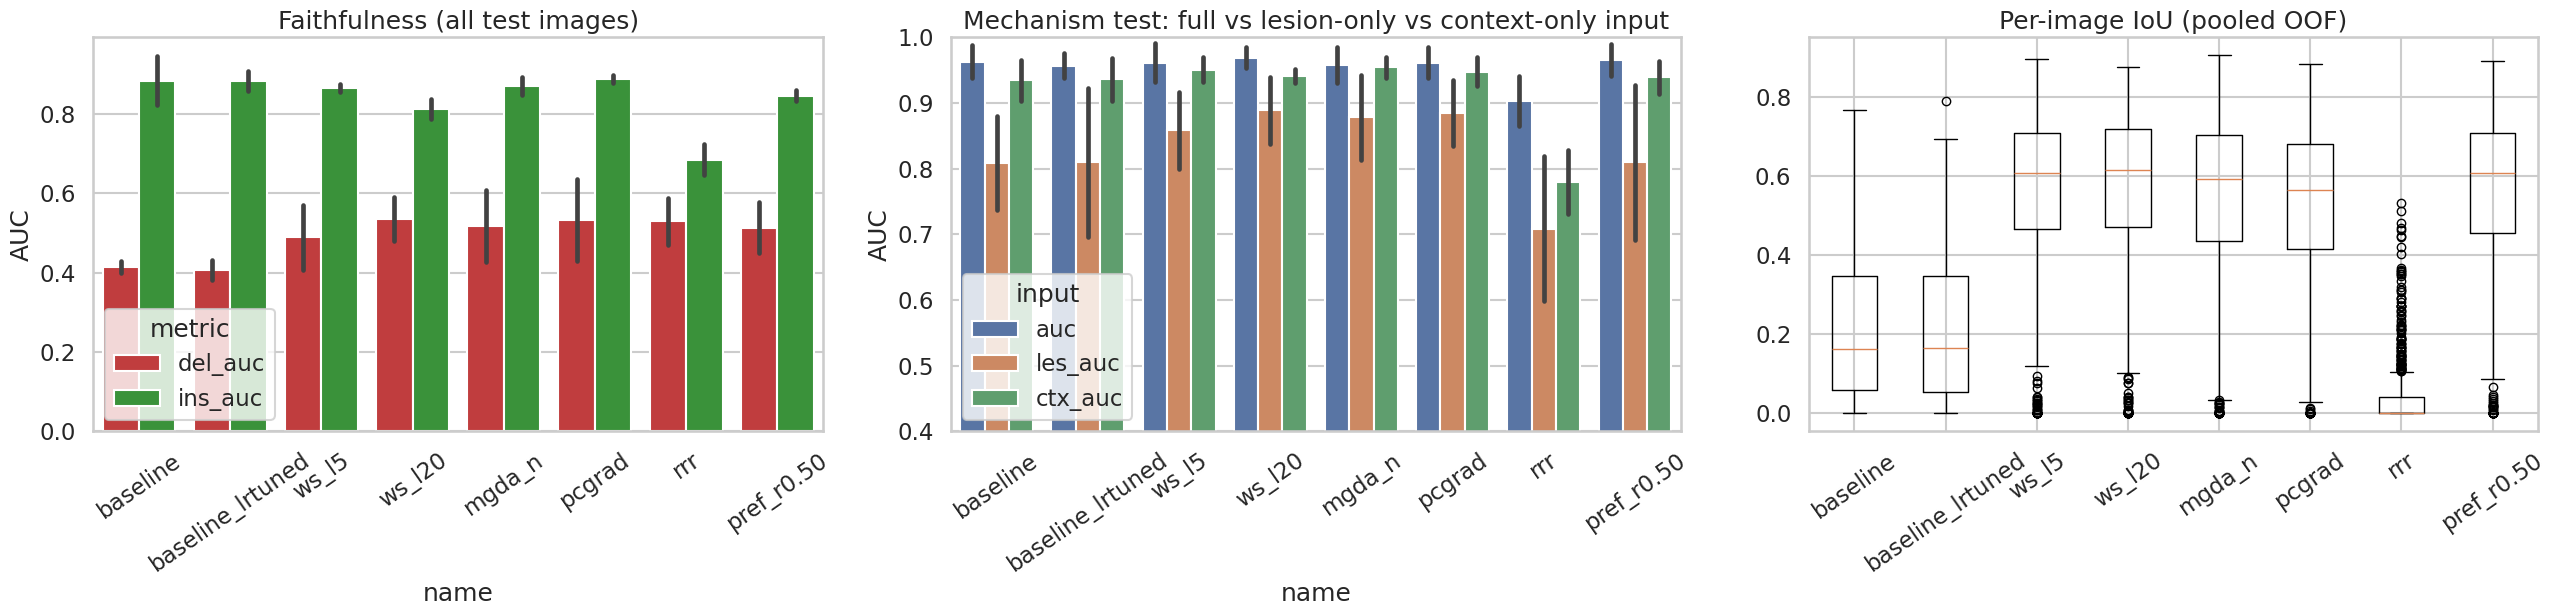

                    auc  les_auc  ctx_auc
name                                     
baseline          0.962    0.809    0.934
baseline_lrtuned  0.957    0.810    0.936
mgda_n            0.958    0.878    0.954
pcgrad            0.961    0.885    0.947
pref_r0.50        0.965    0.809    0.939
rrr               0.903    0.708    0.780
ws_l20            0.969    0.889    0.941
ws_l5             0.961    0.859    0.951


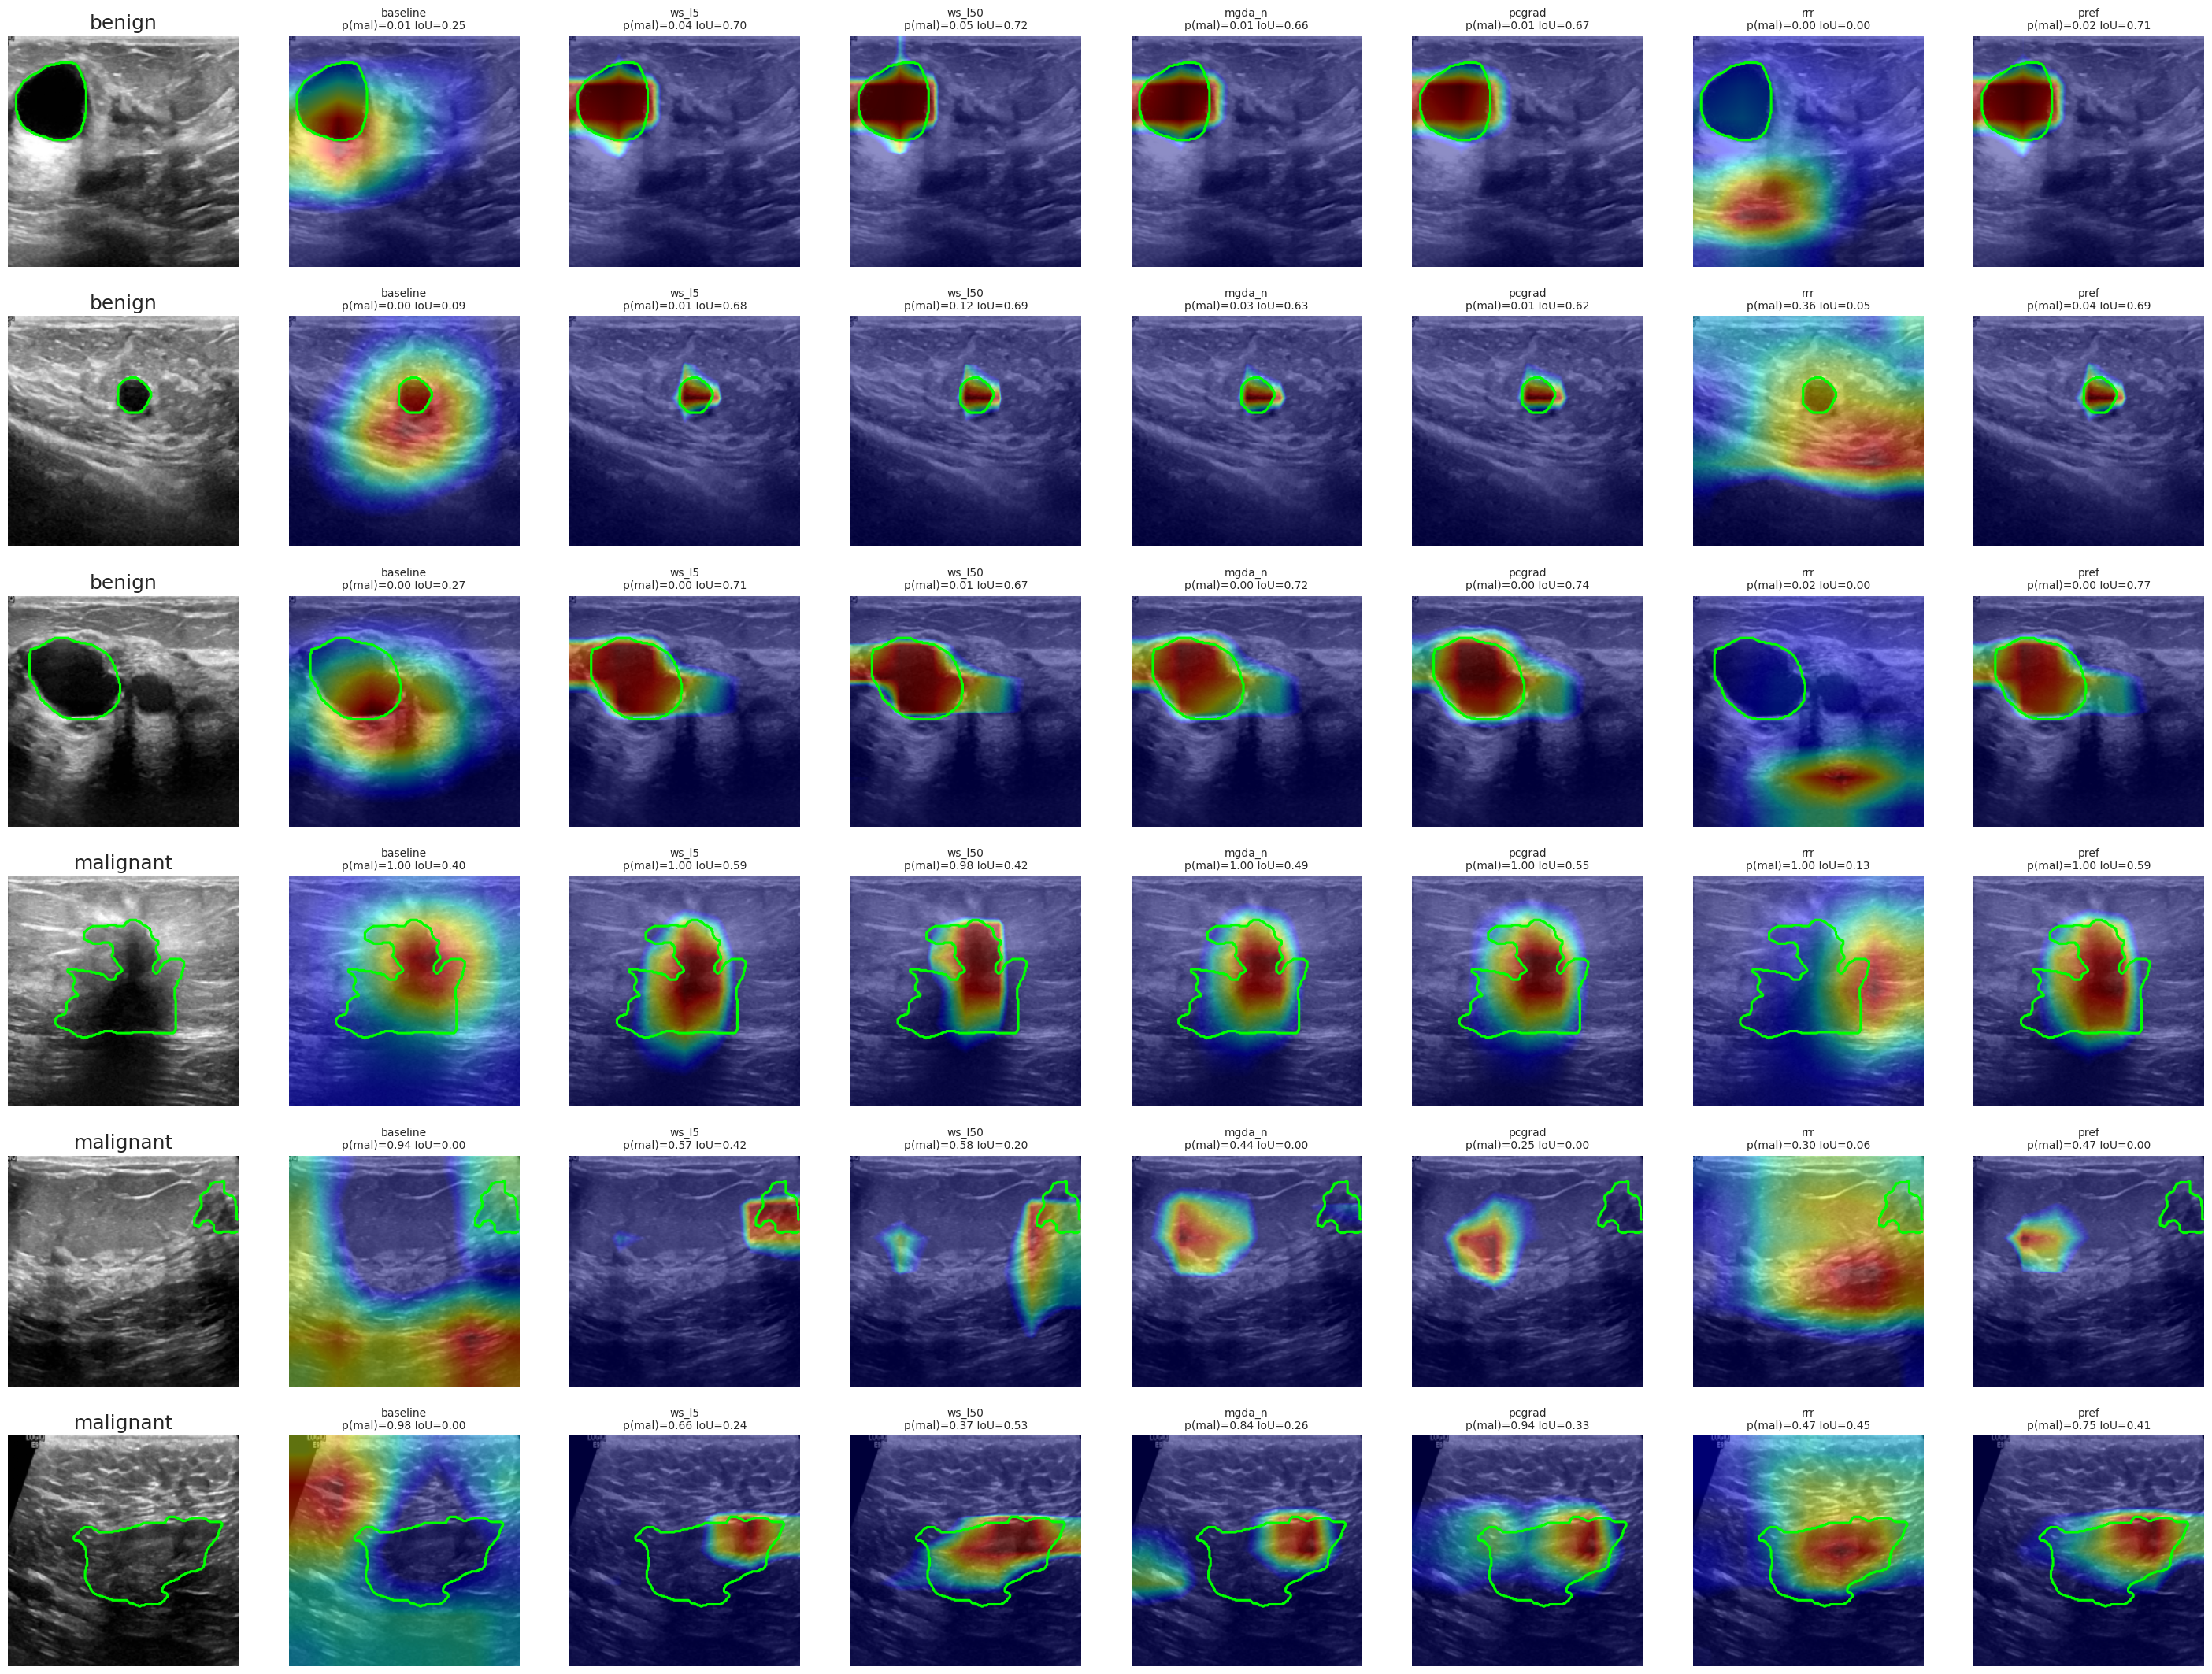

In [13]:
# ---------- 12. Calibration/ROC (pooled out-of-fold), faithfulness, mechanism tests ----------
MAIN = [n for n in ['baseline', 'baseline_lrtuned', 'ws_l5', 'ws_l20', 'mgda_n', 'pcgrad', 'rrr', 'pref_r0.50'] if n in POOL]
cm = dict(zip(MAIN, sns.color_palette('tab10', len(MAIN)))); fig, axs = plt.subplots(1, 2, figsize=(19, 7))
for n in MAIN:
    p1, _ = pooled(n); fpr, tpr, _ = roc_curve(y_T, p1); axs[0].plot(fpr, tpr, lw=2.3, color=cm[n], label=f'{n} (AUC={roc_auc_score(y_T, p1):.3f})')
    conf = np.maximum(p1, 1 - p1); e, cf, ac, cn = ece_bins(conf, ((p1 >= .5) == y_T).astype(float), 8); axs[1].plot(cf, ac, 'o-', color=cm[n], label=f'{n} (ECE={e:.3f})')
axs[0].plot([0, 1], [0, 1], 'k:'); axs[0].set_title(f'Pooled out-of-fold ROC (n={N_T})'); axs[0].legend(fontsize=11); axs[1].plot([.5, 1], [.5, 1], 'k:'); axs[1].set_title('Reliability (pooled OOF)'); axs[1].legend(fontsize=10)
plt.tight_layout(); plt.savefig(f'{FIG}/08_roc_calibration_pooled.png', dpi=200); plt.show()

sel = core[core.name.isin(MAIN)]
fig, axs = plt.subplots(1, 3, figsize=(26, 6.5))
sns.barplot(data=sel.melt(id_vars=['name', 'fold'], value_vars=['del_auc', 'ins_auc'], var_name='metric', value_name='AUC'), x='name', y='AUC', hue='metric', order=MAIN, errorbar='sd', palette=['#d62728', '#2ca02c'], ax=axs[0]); axs[0].set_title('Faithfulness (all test images)')
sns.barplot(data=sel.melt(id_vars=['name', 'fold'], value_vars=['auc', 'les_auc', 'ctx_auc'], var_name='input', value_name='AUC'), x='name', y='AUC', hue='input', order=MAIN, errorbar='sd', ax=axs[1]); axs[1].set_title('Mechanism test: full vs lesion-only vs context-only input'); axs[1].set_ylim(0.4, 1)
axs[2].boxplot([pooled(n)[1] for n in MAIN], labels=MAIN); axs[2].set_title('Per-image IoU (pooled OOF)')
for a in axs: a.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(f'{FIG}/09_faithfulness_mechanism_iou.png', dpi=200); plt.show()
print(sel.groupby('name')[['auc', 'les_auc', 'ctx_auc']].mean().round(3))   # does the model need the lesion? does it use context?

# qualitative CAMs (fold-0 models)
qm = [n for n in ['baseline', 'ws_l5', 'ws_l50', 'mgda_n', 'pcgrad', 'rrr', 'pref'] if n in MODELS]
if qm:
    d0 = make_data(X_all, M_all, y_all, SPLITS[0]); ty = d0['yte'].cpu().numpy(); pick = list(np.where(ty == 0)[0][:3]) + list(np.where(ty == 1)[0][:3]); CAMS = {}
    for n in qm: p_, c_ = predict(MODELS[n], d0['Xte'], [0.5, 0.5] if n == 'pref' else None); CAMS[n] = (p_.cpu().numpy(), c_.cpu().numpy())
    fig, ax = plt.subplots(len(pick), len(qm) + 1, figsize=(3.6 * (len(qm) + 1), 3.6 * len(pick)))
    for r, i in enumerate(pick):
        img, msk = d0['Xte'][i, 0].cpu().numpy(), d0['Mte'][i, 0].cpu().numpy(); ax[r, 0].imshow(img, cmap='gray'); ax[r, 0].contour(msk, [.5], colors='lime'); ax[r, 0].set_title(['benign', 'malignant'][ty[i]])
        for c, n in enumerate(qm):
            pr_, cm_ = CAMS[n]; ax[r, c + 1].imshow(img, cmap='gray'); ax[r, c + 1].imshow(cm_[i, 0], cmap='jet', alpha=.45, vmin=0, vmax=1); ax[r, c + 1].contour(msk, [.5], colors='lime')
            iou = ((cm_[i, 0] >= .5) & (msk > .5)).sum() / max(((cm_[i, 0] >= .5) | (msk > .5)).sum(), 1); ax[r, c + 1].set_title(f'{n}\np(mal)={pr_[i, 1]:.2f} IoU={iou:.2f}', fontsize=10)
    for a in ax.ravel(): a.axis('off')
    plt.tight_layout(); plt.savefig(f'{FIG}/10_qualitative_cams.png', dpi=140); plt.show(); del d0

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 181MB/s]


[resnet50] fold 0 baseline done | 5326s
[resnet50] fold 0 ws_l5 done | 5422s
[resnet50] fold 0 mgda_n done | 5574s
[resnet50] fold 1 baseline done | 5670s
[resnet50] fold 1 ws_l5 done | 5766s
[resnet50] fold 1 mgda_n done | 5918s
[resnet50] fold 2 baseline done | 6014s
[resnet50] fold 2 ws_l5 done | 6111s
[resnet50] fold 2 mgda_n done | 6262s
[resnet50] fold 3 baseline done | 6358s
[resnet50] fold 3 ws_l5 done | 6455s
[resnet50] fold 3 mgda_n done | 6607s
[resnet50] fold 4 baseline done | 6703s
[resnet50] fold 4 ws_l5 done | 6800s
[resnet50] fold 4 mgda_n done | 6952s
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 153MB/s]


[densenet121] fold 0 baseline done | 7050s
[densenet121] fold 0 ws_l5 done | 7147s
[densenet121] fold 0 mgda_n done | 7300s
[densenet121] fold 1 baseline done | 7397s
[densenet121] fold 1 ws_l5 done | 7494s
[densenet121] fold 1 mgda_n done | 7648s
[densenet121] fold 2 baseline done | 7746s
[densenet121] fold 2 ws_l5 done | 7844s
[densenet121] fold 2 mgda_n done | 7998s
[densenet121] fold 3 baseline done | 8096s
[densenet121] fold 3 ws_l5 done | 8194s
[densenet121] fold 3 mgda_n done | 8348s
[densenet121] fold 4 baseline done | 8445s
[densenet121] fold 4 ws_l5 done | 8543s
[densenet121] fold 4 mgda_n done | 8697s
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


[efficientnet_b0] fold 0 baseline done | 8744s
[efficientnet_b0] fold 0 ws_l5 done | 8789s
[efficientnet_b0] fold 0 mgda_n done | 8863s
[efficientnet_b0] fold 1 baseline done | 8909s
[efficientnet_b0] fold 1 ws_l5 done | 8954s
[efficientnet_b0] fold 1 mgda_n done | 9027s
[efficientnet_b0] fold 2 baseline done | 9073s
[efficientnet_b0] fold 2 ws_l5 done | 9119s
[efficientnet_b0] fold 2 mgda_n done | 9192s
[efficientnet_b0] fold 3 baseline done | 9238s
[efficientnet_b0] fold 3 ws_l5 done | 9284s
[efficientnet_b0] fold 3 mgda_n done | 9357s
[efficientnet_b0] fold 4 baseline done | 9403s
[efficientnet_b0] fold 4 ws_l5 done | 9449s
[efficientnet_b0] fold 4 mgda_n done | 9522s


auc           iou        cam_auc        ins_auc  \
                           mean    std   mean    std    mean    std    mean   
arch            cfg                                                           
densenet121     baseline  0.959  0.033  0.222  0.018   0.830  0.025   0.941   
                mgda_n    0.967  0.025  0.552  0.020   0.947  0.019   0.901   
                ws_l5     0.973  0.020  0.567  0.019   0.943  0.020   0.885   
efficientnet_b0 baseline  0.950  0.029  0.279  0.018   0.835  0.035   0.888   
                mgda_n    0.963  0.035  0.516  0.015   0.949  0.013   0.848   
                ws_l5     0.962  0.031  0.543  0.017   0.952  0.015   0.849   
hires           baseline  0.966  0.016  0.267  0.017   0.829  0.022   0.944   
                mgda_n    0.970  0.024  0.622  0.023   0.939  0.017   0.888   
                ws_l5     0.966  0.020  0.632  0.023   0.935  0.024   0.861   
resnet18        baseline  0.962  0.025  0.213  0.021   0.818  0.021   0.884   
                mgda_n    0.958  0.028  0.540  0.019   0.942  0.023   0.871   
                ws_l5     0.961  0.029  0.556  0.021   0.942  0.017   0.866   
resnet50        baseline  0.943  0.017  0.145  0.013   0.818  0.013   0.882   
                mgda_n    0.960  0.033  0.523  0.024   0.941  0.017   0.920   
                ws_l5     0.956  0.031  0.553  0.024   0.942  0.019   0.895   

                                del_auc         
                            std    mean    std  
arch            cfg                             
densenet121     baseline  0.010   0.417  0.041  
                mgda_n    0.009   0.544  0.047  
                ws_l5     0.005   0.566  0.074  
efficientnet_b0 baseline  0.038   0.484  0.019  
                mgda_n    0.022   0.539  0.039  
                ws_l5     0.002   0.532  0.019  
hires           baseline  0.006   0.419  0.058  
                mgda_n    0.008   0.568  0.059  
                ws_l5     0.014   0.588  0.061  
resnet18        baseline  0.062   0.415  0.016  
                mgda_n    0.022   0.518  0.090  
                ws_l5     0.010   0.489  0.082  
resnet50        baseline  0.094   0.443  0.036  
                mgda_n    0.009   0.510  0.045  
                ws_l5     0.028   0.556  0.036

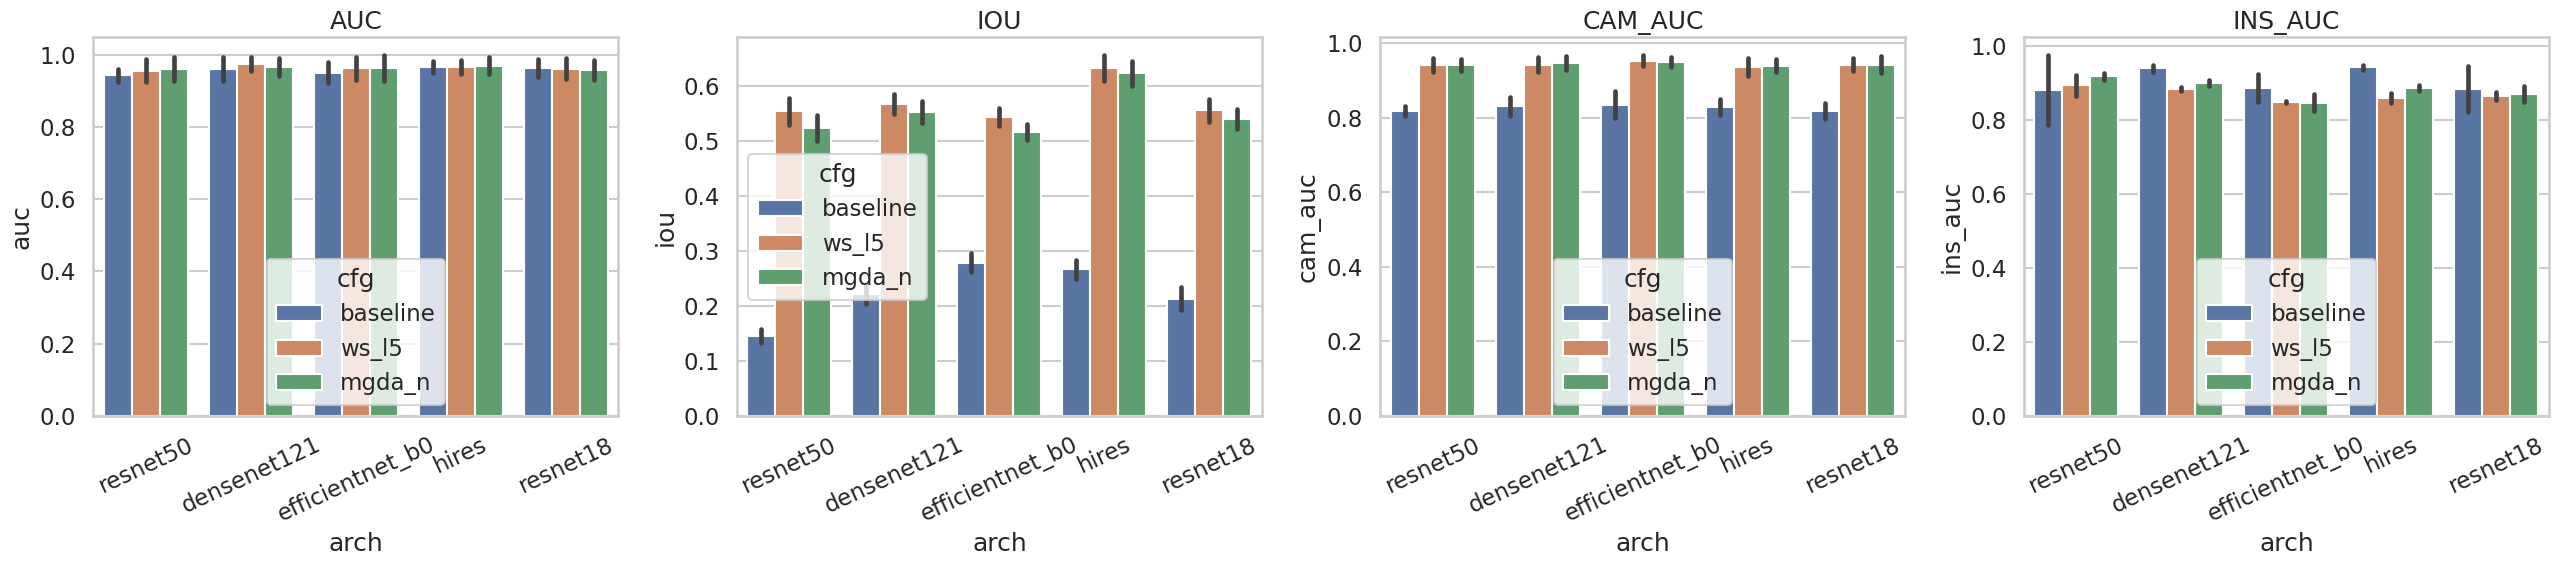

In [14]:
# ---------- 13. Robustness checks: other backbones + higher-resolution CAMs ----------
if RUN['backbones']:
    for arch in CFG['BACKBONES']:
        for sp in SPLITS:
            data = make_data(X_all, M_all, y_all, sp)
            for name in CFG['BACKBONE_CONFIGS']:
                m = run_exp(name, sp, data, arch=arch, prefix=f'{arch}|', fam=arch); del m; torch.cuda.empty_cache()
                print(f"[{arch}] fold {sp['fold']} {name} done | {time.time() - T0:.0f}s")
            del data
if RUN['highres']:
    for sp in SPLITS:
        data = make_data(X_all, M_all, y_all, sp)
        for name in CFG['BACKBONE_CONFIGS']:
            m = run_exp(name, sp, data, highres=True, prefix='hires|', fam='hires-CAM'); del m; torch.cuda.empty_cache()
        del data
RES = pd.DataFrame(ROWS); RES.to_csv(f'{OUT}/runs_all_test_metrics.csv', index=False)
ext = RES[RES.name.str.contains(r'\|')].copy()
if len(ext):
    ext['arch'] = ext.name.str.split('|').str[0]; ext['cfg'] = ext.name.str.split('|').str[1]
    for n in CFG['BACKBONE_CONFIGS']:                                     # add ResNet-18 low-res reference
        r0 = core[core.name == n].copy(); r0['arch'] = 'resnet18'; r0['cfg'] = n; ext = pd.concat([ext, r0])
    display(ext.groupby(['arch', 'cfg'])[['auc', 'iou', 'cam_auc', 'ins_auc', 'del_auc']].agg(['mean', 'std']).round(3))
    fig, axs = plt.subplots(1, 4, figsize=(26, 6))
    for a, c in zip(axs, ['auc', 'iou', 'cam_auc', 'ins_auc']): sns.barplot(data=ext, x='arch', y=c, hue='cfg', errorbar='sd', ax=a); a.tick_params(axis='x', rotation=25); a.set_title(c.upper())
    plt.tight_layout(); plt.savefig(f'{FIG}/11_backbones_and_highres.png', dpi=200); plt.show()
    ext.to_csv(f'{OUT}/backbones_highres.csv', index=False)

[shortcut fold 0] baseline done
[shortcut fold 0] ws_l1 done
[shortcut fold 0] ws_l5 done
[shortcut fold 0] ws_l20 done
[shortcut fold 0] mgda_n done
[shortcut fold 0] rrr done
[shortcut fold 1] baseline done
[shortcut fold 1] ws_l1 done
[shortcut fold 1] ws_l5 done
[shortcut fold 1] ws_l20 done
[shortcut fold 1] mgda_n done
[shortcut fold 1] rrr done
[shortcut fold 2] baseline done
[shortcut fold 2] ws_l1 done
[shortcut fold 2] ws_l5 done
[shortcut fold 2] ws_l20 done
[shortcut fold 2] mgda_n done
[shortcut fold 2] rrr done
[shortcut fold 3] baseline done
[shortcut fold 3] ws_l1 done
[shortcut fold 3] ws_l5 done
[shortcut fold 3] ws_l20 done
[shortcut fold 3] mgda_n done
[shortcut fold 3] rrr done
[shortcut fold 4] baseline done
[shortcut fold 4] ws_l1 done
[shortcut fold 4] ws_l5 done
[shortcut fold 4] ws_l20 done
[shortcut fold 4] mgda_n done
[shortcut fold 4] rrr done


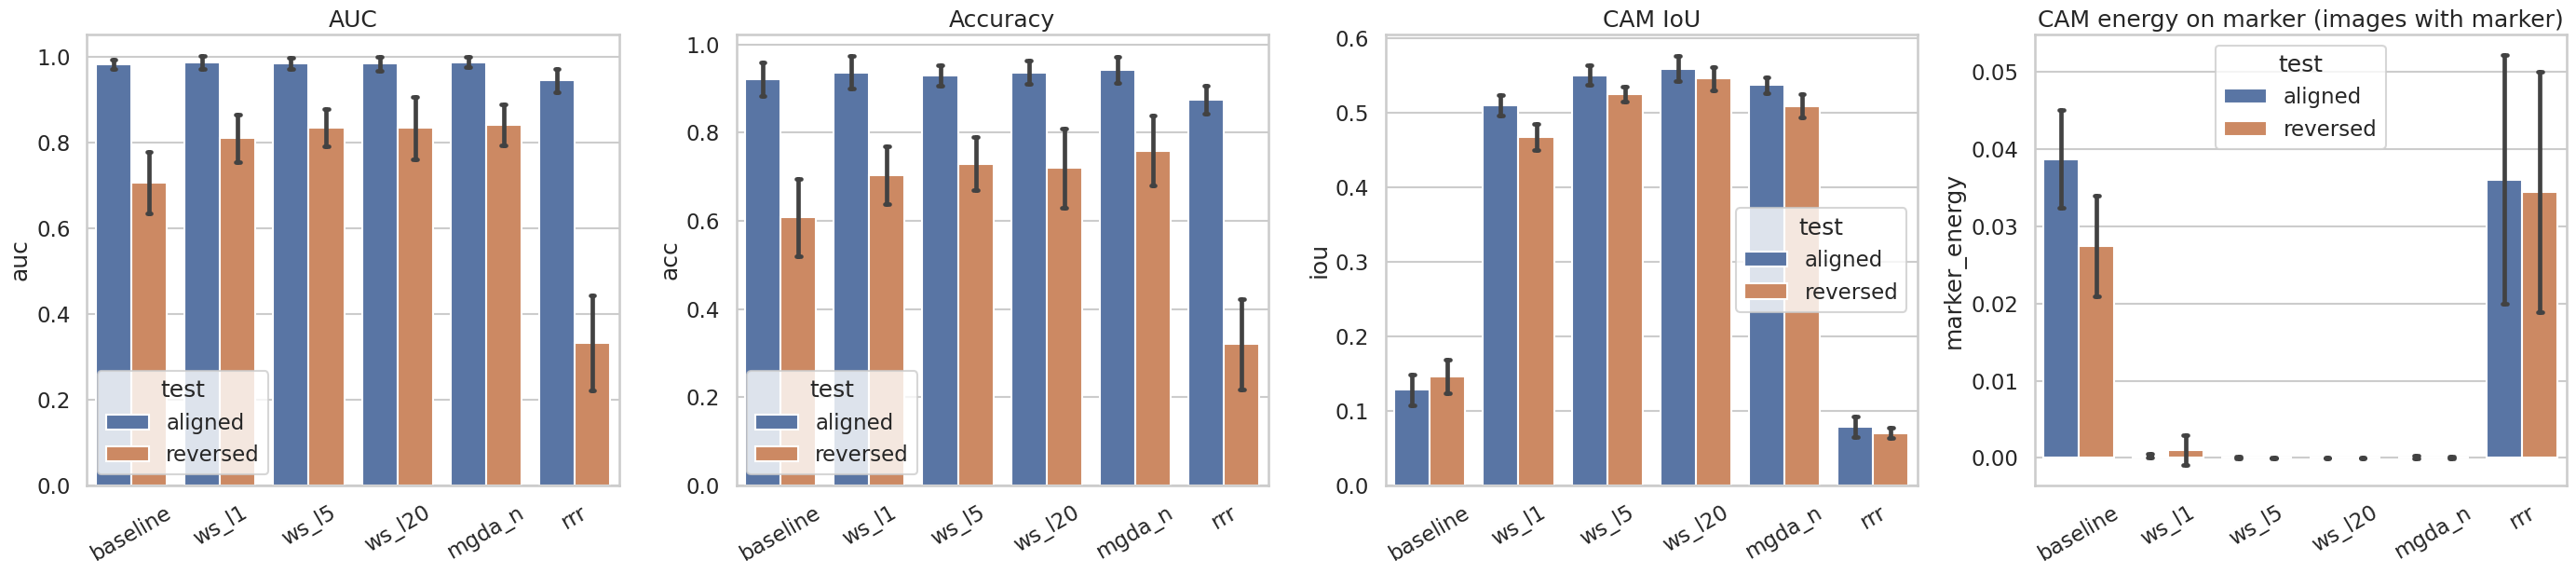

mean              std             gap
test     aligned reversed aligned reversed       
method                                           
baseline   0.982    0.706   0.012    0.073  0.276
mgda_n     0.987    0.840   0.012    0.048  0.147
rrr        0.944    0.333   0.026    0.111  0.611
ws_l1      0.986    0.810   0.015    0.055  0.176
ws_l20     0.983    0.834   0.016    0.073  0.149
ws_l5      0.984    0.835   0.013    0.043  0.149

ws_l1    reversed AUC 0.810 vs baseline 0.706 | paired t p=0.0028
ws_l5    reversed AUC 0.835 vs baseline 0.706 | paired t p=0.0018
ws_l20   reversed AUC 0.834 vs baseline 0.706 | paired t p=0.0046
mgda_n   reversed AUC 0.840 vs baseline 0.706 | paired t p=0.0006
rrr      reversed AUC 0.333 vs baseline 0.706 | paired t p=0.0035


In [15]:
# ---------- 14. Controlled shortcut experiment (5-fold) with CAM energy on the marker ----------
if RUN['shortcut']:
    def add_marker(X, flag):
        X = X.clone(); X[flag, :, 8:28, 8:28] = 255; return X
    def marker_flags(y, p_mal, seed):
        g_ = torch.Generator().manual_seed(seed); u = torch.rand(len(y), generator=g_); return torch.where(y == 1, u < p_mal, u < (1 - p_mal))
    MK = torch.zeros(1, 1, S, S, device=DEVICE); MK[..., 8:28, 8:28] = 1; cf_rows = []
    for sp in SPLITS:
        k = sp['fold']; flag = torch.zeros(N, dtype=torch.bool)
        for key, off in [('tr', 1), ('va', 2), ('te', 3)]: flag[sp[key]] = marker_flags(y_all[sp[key]], 0.9, 10 * k + off)
        dataC = make_data(add_marker(X_all, flag), M_all, y_all, sp)
        fl_rev = marker_flags(y_all[sp['te']], 0.1, 10 * k + 3); Xrev = add_marker(X_all[sp['te']], fl_rev).to(DEVICE)
        for name in CFG['SHORTCUT_CONFIGS']:
            m = run_exp(name, sp, dataC, prefix='sc|', fam='shortcut')            # logs clean-protocol metrics on aligned test too
            for split_, Xs, fl in [('aligned', dataC['Xte'], flag[sp['te']]), ('reversed', Xrev, fl_rev)]:
                p, c = predict(m, Xs); mm, _, _ = compute_metrics(p, dataC['yte'], c, dataC['Mte']); fl = fl.to(DEVICE)
                me = ((c * MK).sum((1, 2, 3)) / c.sum((1, 2, 3)).clamp(min=1e-6))[fl].mean().item() if fl.any() else np.nan
                cf_rows.append(dict(method=name, fold=k, test=split_, auc=mm['auc'], acc=mm['acc'], iou=mm['iou'], marker_energy=me))
            del m; torch.cuda.empty_cache(); print(f'[shortcut fold {k}] {name} done')
        del dataC
    CF = pd.DataFrame(cf_rows); CF.to_csv(f'{OUT}/shortcut_experiment.csv', index=False)
    fig, axs = plt.subplots(1, 4, figsize=(28, 6.5))
    for a, c, t in zip(axs, ['auc', 'acc', 'iou', 'marker_energy'], ['AUC', 'Accuracy', 'CAM IoU', 'CAM energy on marker (images with marker)']):
        sns.barplot(data=CF, x='method', y=c, hue='test', errorbar='sd', capsize=.1, palette=['#4c72b0', '#dd8452'], ax=a); a.set_title(t); a.tick_params(axis='x', rotation=30); a.set_xlabel('')
    plt.tight_layout(); plt.savefig(f'{FIG}/12_shortcut_test.png', dpi=200); plt.show()
    piv = CF.pivot_table(index='method', columns='test', values='auc', aggfunc=['mean', 'std']).round(3); piv['gap'] = (piv[('mean', 'aligned')] - piv[('mean', 'reversed')]).round(3); display(piv)
    bsl = CF[(CF.method == 'baseline') & (CF.test == 'reversed')].sort_values('fold').auc.values              # paired fold tests vs baseline (reversed AUC)
    for n in [m_ for m_ in CF.method.unique() if m_ != 'baseline']:
        v = CF[(CF.method == n) & (CF.test == 'reversed')].sort_values('fold').auc.values; print(f'{n:8s} reversed AUC {v.mean():.3f} vs baseline {bsl.mean():.3f} | paired t p={stats.ttest_rel(v, bsl).pvalue:.4f}')

,lam,lr,dil,val_auc,val_iou,test_auc,test_iou,front
21,0.4551,0.0005,9,0.9913,0.3724,0.9786,0.3941,True
22,1.7551,0.0008,4,0.9729,0.5178,0.9716,0.5118,True
25,1.6055,0.0007,3,0.9762,0.5098,0.9656,0.5338,True
26,1.7551,0.0008,4,0.9816,0.5021,0.9513,0.5060,True
29,6.6899,0.0008,3,0.9545,0.5307,0.9640,0.5376,True
30,13.8063,0.0009,3,0.9383,0.5312,0.9462,0.5383,True
31,0.2929,0.0002,9,0.9838,0.3816,0.9621,0.3747,True


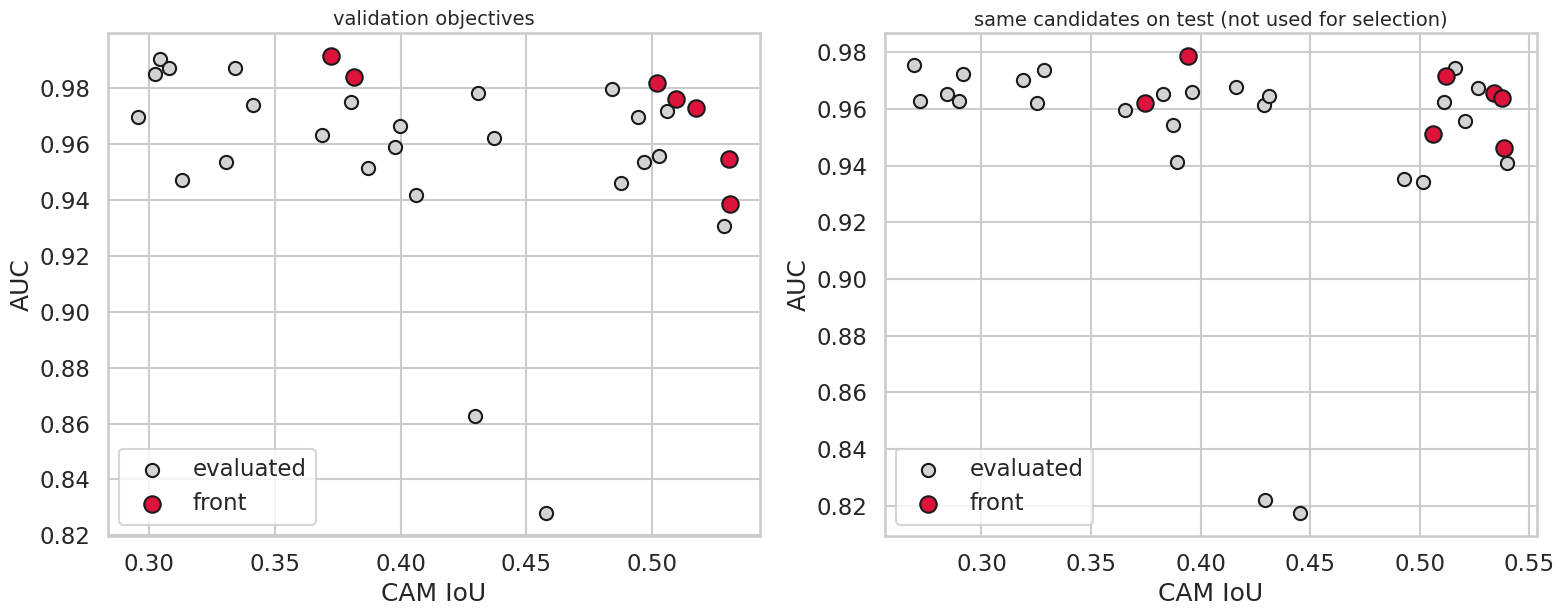

In [16]:
# ---------- 15. NSGA-II hyper-parameter search (fold 0, validation objectives) ----------
if RUN['nsga2']:
    from pymoo.algorithms.moo.nsga2 import NSGA2
    from pymoo.core.problem import ElementwiseProblem
    from pymoo.optimize import minimize
    d0 = make_data(X_all, M_all, y_all, SPLITS[0]); NSGA_LOG = []
    class HPO(ElementwiseProblem):
        def __init__(self): super().__init__(n_var=3, n_obj=2, xl=np.array([-1.5, -4.5, 0.0]), xu=np.array([2.0, -3.0, 20.0]))
        def _evaluate(self, x, out, *a, **k):
            lam, lr, dil = 10 ** x[0], 10 ** x[1], int(round(x[2]))
            m, h = train_run('ws', lam, dil, 'dice', 0, d0, epochs=CFG['NSGA_EPOCHS'], lr=lr)
            p, c = predict(m, d0['Xte']); tm, _, _ = compute_metrics(p, d0['yte'], c, d0['Mte'])
            NSGA_LOG.append(dict(lam=lam, lr=lr, dil=dil, val_auc=h.val_auc.iloc[-1], val_iou=h.val_iou.iloc[-1], test_auc=tm['auc'], test_iou=tm['iou']))
            out['F'] = [1 - h.val_auc.iloc[-1], 1 - h.val_iou.iloc[-1]]; del m; torch.cuda.empty_cache()
    res = minimize(HPO(), NSGA2(pop_size=CFG['NSGA_POP']), ('n_gen', CFG['NSGA_GEN']), seed=1, verbose=False)
    NG = pd.DataFrame(NSGA_LOG); NG['front'] = [bool(any(np.allclose([1 - r.val_auc, 1 - r.val_iou], f_row, atol=1e-9) for f_row in np.atleast_2d(res.F))) for r in NG.itertuples()]
    NG.to_csv(f'{OUT}/nsga2_log.csv', index=False); display(NG[NG.front].round(4))
    fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
    for a, (xa, ya, t) in zip(axs, [('val_iou', 'val_auc', 'validation objectives'), ('test_iou', 'test_auc', 'same candidates on test (not used for selection)')]):
        a.scatter(NG[xa], NG[ya], c='lightgray', s=90, edgecolor='k', label='evaluated'); a.scatter(NG[NG.front][xa], NG[NG.front][ya], c='crimson', s=140, edgecolor='k', label='front'); a.set_xlabel('CAM IoU'); a.set_ylabel('AUC'); a.set_title(t, fontsize=14); a.legend()
    plt.tight_layout(); plt.savefig(f'{FIG}/13_nsga2.png', dpi=200); plt.show(); del d0

In [19]:
# ---------- 16. Optional external validation (train on ALL of BUSI, test on another dataset) ----------
# Build EXT_DF yourself (columns: path, mask_paths (list), label 0/1) for BUS-BRA / UDIAT / BrEaST, keeping only benign+malignant with a lesion mask.
# Then set RUN['external']=True. Images are resized/normalised exactly like BUSI. Example:
#   EXT_DF = pd.DataFrame([dict(path='.../img_001.png', mask_paths=['.../mask_001.png'], label=1), ...])
EXT_DF = None
if RUN['external'] and EXT_DF is not None:
    its = [load_item(r.path, r.mask_paths) for r in EXT_DF.itertuples()]
    Xe = torch.from_numpy(np.stack([i[0] for i in its]))[:, None].to(DEVICE); Me = torch.from_numpy(np.stack([i[1] for i in its]))[:, None].to(DEVICE); ye = torch.tensor(EXT_DF.label.values).to(DEVICE)
    tr_all, va_all = train_test_split(np.arange(N), test_size=0.1, stratify=y_np, random_state=0); dall = make_data(X_all, M_all, y_all, dict(tr=tr_all, va=va_all, te=va_all)); ext_rows = []
    for name in ['baseline', 'ws_l5', 'mgda_n', 'rrr']:
        for seed in range(3):
            _, method, lam, dil, kind, _ = EXP[name]; m, _ = train_run(method, lam, dil, kind, seed, dall)
            p, c = predict(m, Xe); mm, _, _ = compute_metrics(p, ye, c, Me); ext_rows.append(dict(method=name, seed=seed, **mm)); del m
    EXT_RES = pd.DataFrame(ext_rows); EXT_RES.to_csv(f'{OUT}/external_validation.csv', index=False)
    display(EXT_RES.groupby('method')[['auc', 'sens', 'spec', 'iou', 'cam_auc']].agg(['mean', 'std']).round(3))

In [20]:
# ---------- 17. Automatic findings + export ----------
M_ = MEANS[~MEANS.family.isin(['Ablation'])]
for c, lab in [('auc', 'Highest AUC'), ('iou', 'Highest IoU'), ('ins_auc', 'Highest insertion (faithfulness)')]:
    r = M_.loc[M_[c].idxmax()]; print(f"{lab:34s}: {r['name']:16s} AUC={r['auc']:.3f} IoU={r['iou']:.3f} Ins={r['ins_auc']:.3f}")
b = M_[M_.name == 'baseline'].iloc[0]; print(f"Baseline: AUC={b['auc']:.3f} IoU={b['iou']:.3f} Ins={b['ins_auc']:.3f}")
hvm = HV.groupby('method')[['HV_auc_iou']].mean(); print('Hypervolume (AUC,IoU):\n', hvm.round(4).to_string())
print('Check: is there a trade-off at large λ? AUC by λ ->', ws.groupby('lam').auc.mean().round(3).to_dict())
print('Tables:', sorted(os.listdir(OUT))); print('Figures:', sorted(os.listdir(FIG)))
shutil.make_archive('bus_multiobjective_results_v2', 'zip', OUT)
try:
    from google.colab import files; files.download('bus_multiobjective_results_v2.zip')
except Exception as e: print('Download manually:', e)

Highest AUC                       : ws_l10           AUC=0.973 IoU=0.559 Ins=0.845
Highest IoU                       : ws_l50           AUC=0.946 IoU=0.565 Ins=0.735
Highest insertion (faithfulness)  : ws_l0.1          AUC=0.967 IoU=0.378 Ins=0.908
Baseline: AUC=0.962 IoU=0.213 Ins=0.884
Hypervolume (AUC,IoU):
               HV_auc_iou
method                  
All               0.2717
MGDA              0.2547
MGDA-N            0.2473
PCGrad            0.2404
PrefCond          0.2588
RRR               0.0173
WS (λ sweep)      0.2709
Check: is there a trade-off at large λ? AUC by λ -> {0.0: 0.962, 0.1: 0.967, 0.5: 0.968, 1.0: 0.966, 2.0: 0.969, 5.0: 0.961, 10.0: 0.973, 20.0: 0.969, 50.0: 0.946}
Tables: ['backbones_highres.csv', 'figs', 'hypervolume.csv', 'nsga2_log.csv', 'paired_vs_baseline_folds.csv', 'pooled_oof_stats.csv', 'pref_model_diagnostics.json', 'runs_all_test_metrics.csv', 'runs_main.csv', 'shortcut_experiment.csv', 'summary_mean_sd_over_folds.csv']
Figures: ['00_dataset_samp

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>